> **Revised version.** Fixes: mixed-effects crash, non-idempotent column drop, missing pip packages, broken Stage 1 stacking, optimistic blending threshold, near-uniform weighted averaging, plus a new F1 comparison (3.13f). Outputs from the first changed cell onward were cleared because the old numbers no longer apply: use *Run All*.

In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/busygeek/smx-concentration/SMX_concentration.csv
/kaggle/input/datasets/busygeek/smx-concentration/SMX_occurrence.csv


In [4]:
df_occ=pd.read_csv("/kaggle/input/datasets/busygeek/smx-concentration/SMX_occurrence.csv")
df_conc=pd.read_csv("/kaggle/input/datasets/busygeek/smx-concentration/SMX_concentration.csv")

In [5]:
print('occurrence:', df_occ.shape, '| concentration:', df_conc.shape)

occurrence: (1502, 41) | concentration: (871, 37)


In [6]:
df_occ.shape

(1502, 41)

In [7]:
df_occ.head()

,site_id,country,latitude,longitude,sampling_date,water_matrix,concentration_ng_L,LoD,LoQ,detection_status,...,dist_to_urban_area,pH,EC,TOC,COD,nutrients,turbidity,suspended_solids,Y_occ,Y_det
0,771,Italy,45.551944,8.973056,2006-12-13,river/lake,131.0,0.5,1.0,quantified,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1
1,772,Italy,45.518889,9.041944,2006-12-13,river/lake,117.0,0.5,1.0,quantified,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1
2,773,Italy,45.296667,9.388889,2006-06-29,river/lake,60.0,0.5,1.0,quantified,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1
3,774,Italy,45.538056,9.182222,2006-10-04,river/lake,49.0,0.5,1.0,quantified,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1
4,775,Italy,45.889167,11.605000,2006-06-29,river/lake,13.0,0.5,1.0,quantified,...,0.141435,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1


In [8]:
df_conc.head()

,site_id,country,latitude,longitude,sampling_date,water_matrix,concentration_ng_L,month,year,day_of_year,...,dist_to_WWTP,dist_to_urban_area,pH,EC,TOC,COD,nutrients,turbidity,suspended_solids,Y_conc
0,771,Italy,45.551944,8.973056,2006-12-13,river/lake,131.0,12.0,2006.0,347.0,...,1.245786,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.120574
1,772,Italy,45.518889,9.041944,2006-12-13,river/lake,117.0,12.0,2006.0,347.0,...,4.349366,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.071882
2,773,Italy,45.296667,9.388889,2006-06-29,river/lake,60.0,6.0,2006.0,180.0,...,0.782883,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.785330
3,774,Italy,45.538056,9.182222,2006-10-04,river/lake,49.0,10.0,2006.0,277.0,...,1.940980,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.698970
4,775,Italy,45.889167,11.605000,2006-06-29,river/lake,13.0,6.0,2006.0,180.0,...,8.793537,0.141435,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.146128


In [9]:
missing = pd.DataFrame({
    'Missing Count': df_occ.isnull().sum(),
    'Missing Percentage': (df_occ.isnull().sum() / len(df_occ)) * 100
})

missing = missing.sort_values('Missing Percentage', ascending=False)

print(missing)

                     Missing Count  Missing Percentage
COD                           1502          100.000000
turbidity                     1498           99.733688
nutrients                     1469           97.802929
TOC                           1416           94.274301
suspended_solids              1406           93.608522
pH                            1349           89.813582
EC                            1331           88.615180
rainfall_anomaly               249           16.577896
air_temperature                225           14.980027
evapotranspiration             225           14.980027
rainfall_1d                    225           14.980027
rainfall_7d                    225           14.980027
rainfall_30d                   225           14.980027
population_density             162           10.785619
month_sin                      144            9.587217
season                         144            9.587217
month                          144            9.587217
sampling_d

In [10]:
missing = pd.DataFrame({
    'Missing Count': df_conc.isnull().sum(),
    'Missing Percentage': (df_conc.isnull().sum() / len(df_conc)) * 100
})

missing = missing.sort_values('Missing Percentage', ascending=False)

print(missing)

                     Missing Count  Missing Percentage
COD                            871          100.000000
turbidity                      869           99.770379
nutrients                      848           97.359357
TOC                            798           91.618829
suspended_solids               789           90.585534
pH                             750           86.107922
EC                             739           84.845006
rainfall_anomaly                90           10.332951
rainfall_1d                     75            8.610792
air_temperature                 75            8.610792
rainfall_30d                    75            8.610792
evapotranspiration              75            8.610792
rainfall_7d                     75            8.610792
season                          59            6.773823
month_cos                       59            6.773823
month                           59            6.773823
month_sin                       59            6.773823
sampling_d

In [11]:
df_occ = df_occ.drop(columns=df_occ.columns[df_occ.isnull().mean() >= 0.70])

In [12]:
df_conc = df_conc.drop(columns=df_conc.columns[df_conc.isnull().mean() >= 0.70])

In [13]:
df_occ.drop(columns=['pct_industrial_land','day_of_year'], inplace=True, errors='ignore')
df_conc.drop(columns=['pct_industrial_land', 'day_of_year'], inplace=True, errors='ignore')

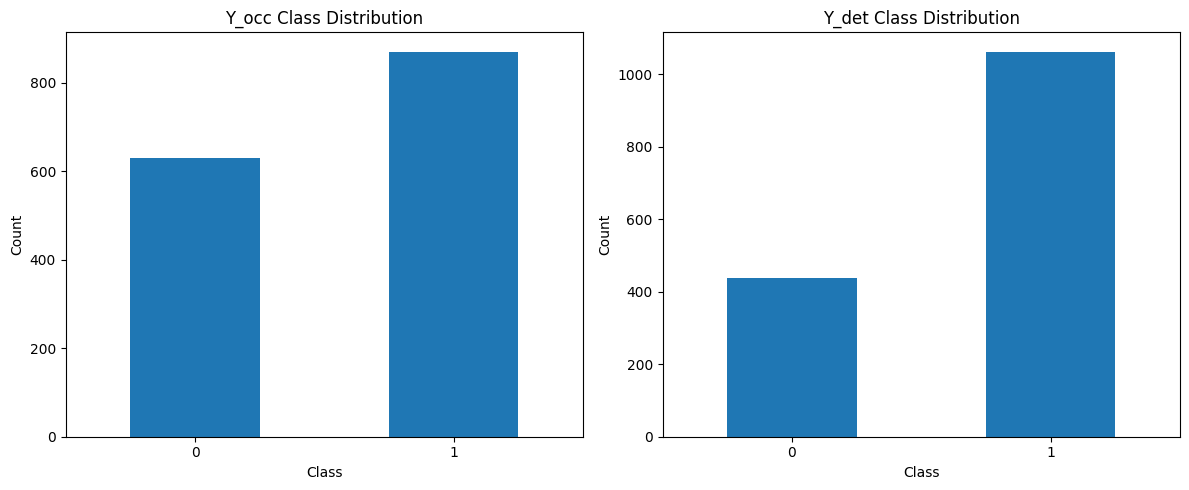

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ---------------- Y_occ ----------------
df_occ['Y_occ'].value_counts().sort_index().plot(
    kind='bar',
    ax=axes[0]
)

axes[0].set_title('Y_occ Class Distribution')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')
axes[0].set_xticklabels(['0', '1'], rotation=0)

# ---------------- Y_det ----------------
df_occ['Y_det'].value_counts().sort_index().plot(
    kind='bar',
    ax=axes[1]
)

axes[1].set_title('Y_det Class Distribution')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Count')
axes[1].set_xticklabels(['0', '1'], rotation=0)

plt.tight_layout()
plt.show()

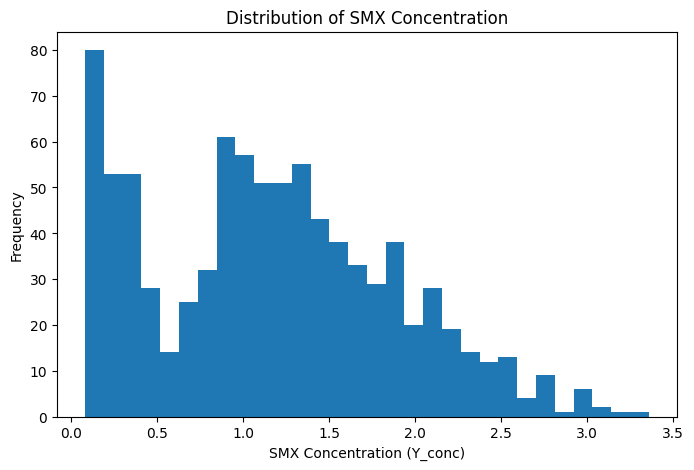

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_conc['Y_conc'].dropna(),
    bins=30
)

plt.xlabel('SMX Concentration (Y_conc)')
plt.ylabel('Frequency')
plt.title('Distribution of SMX Concentration')

plt.show()

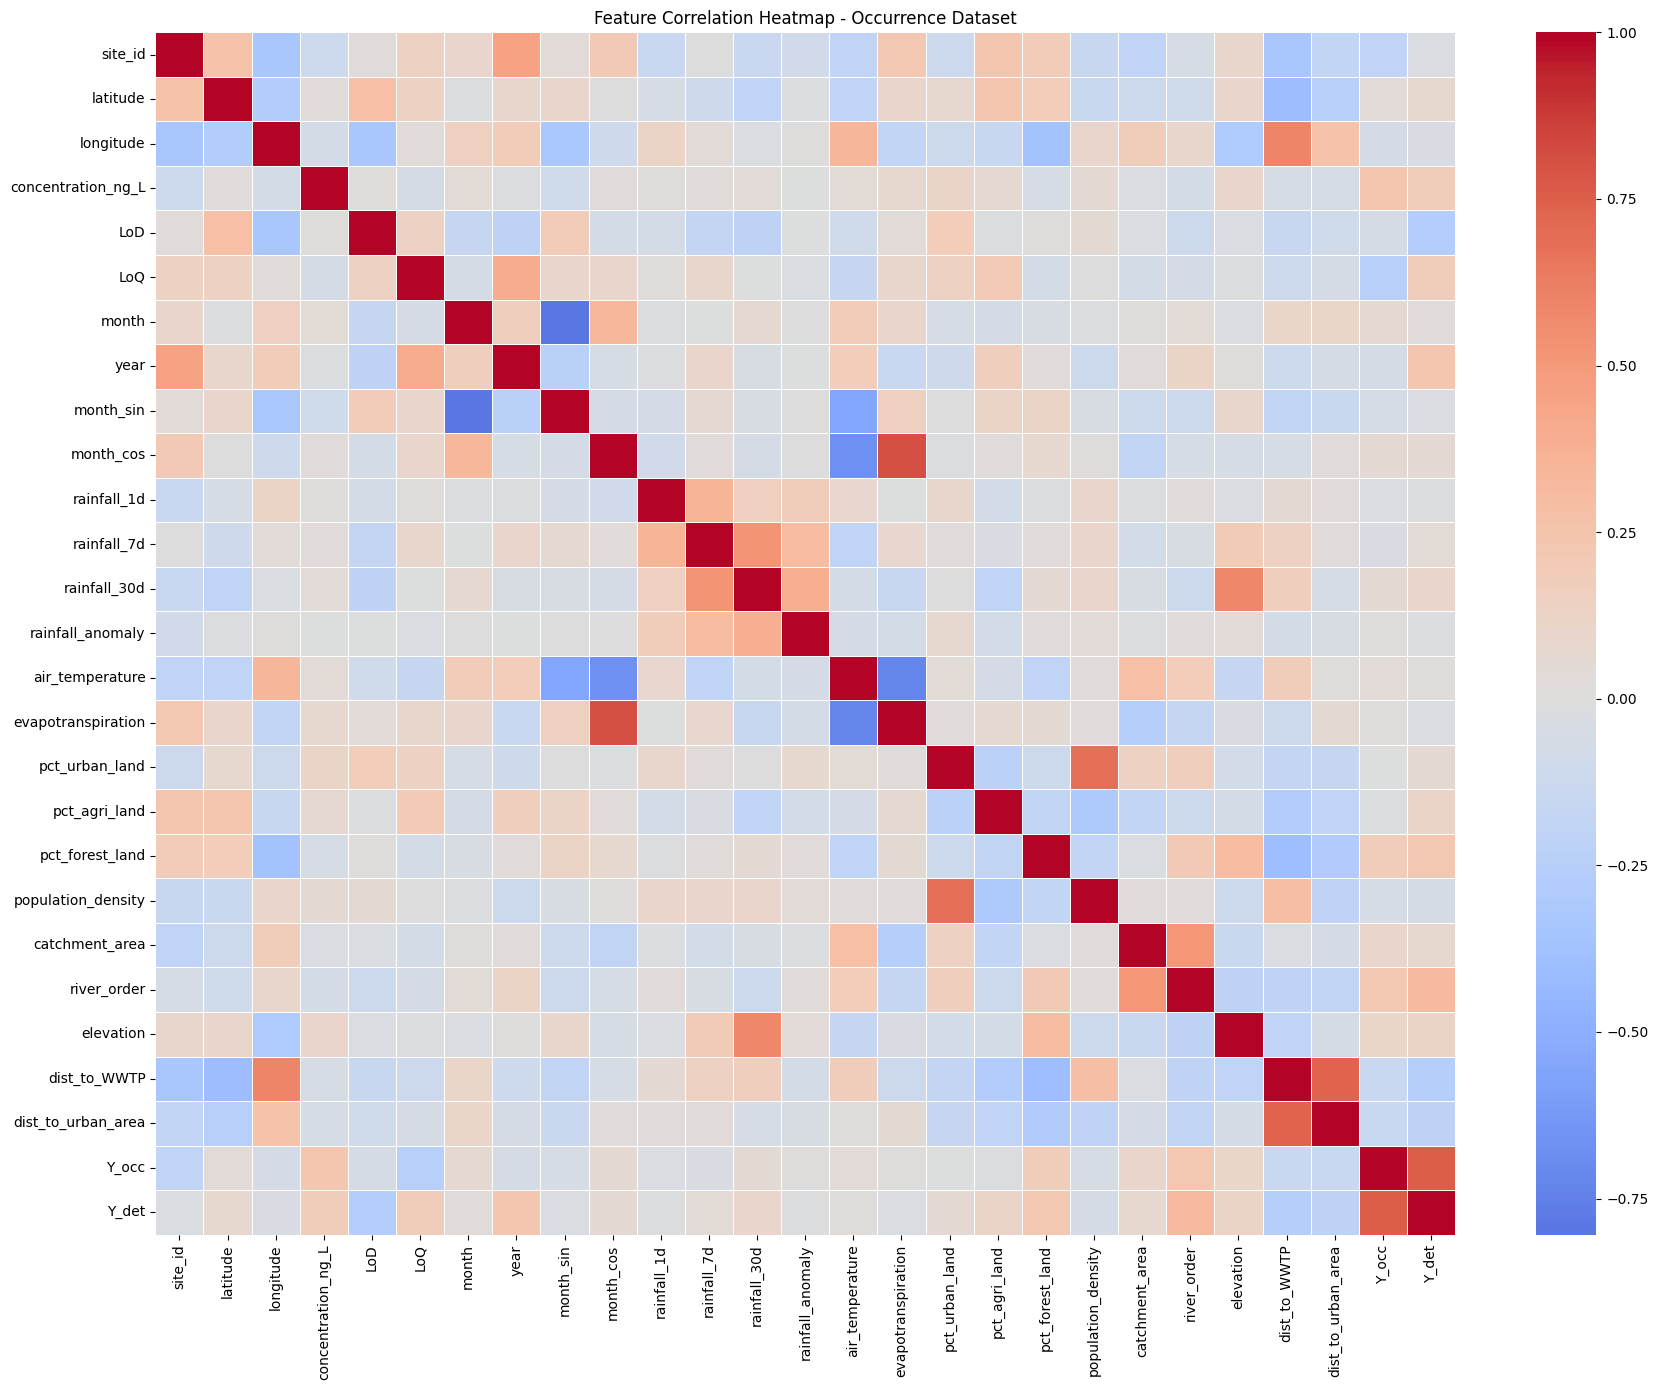

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numeric_occ = df_occ.select_dtypes(include='number')

# Correlation matrix
corr_occ = numeric_occ.corr()

# Plot
plt.figure(figsize=(18, 14))

sns.heatmap(
    corr_occ,
    cmap='coolwarm',
    center=0,
    annot=False,
    linewidths=0.5
)

plt.title('Feature Correlation Heatmap - Occurrence Dataset')
plt.tight_layout()
plt.show()

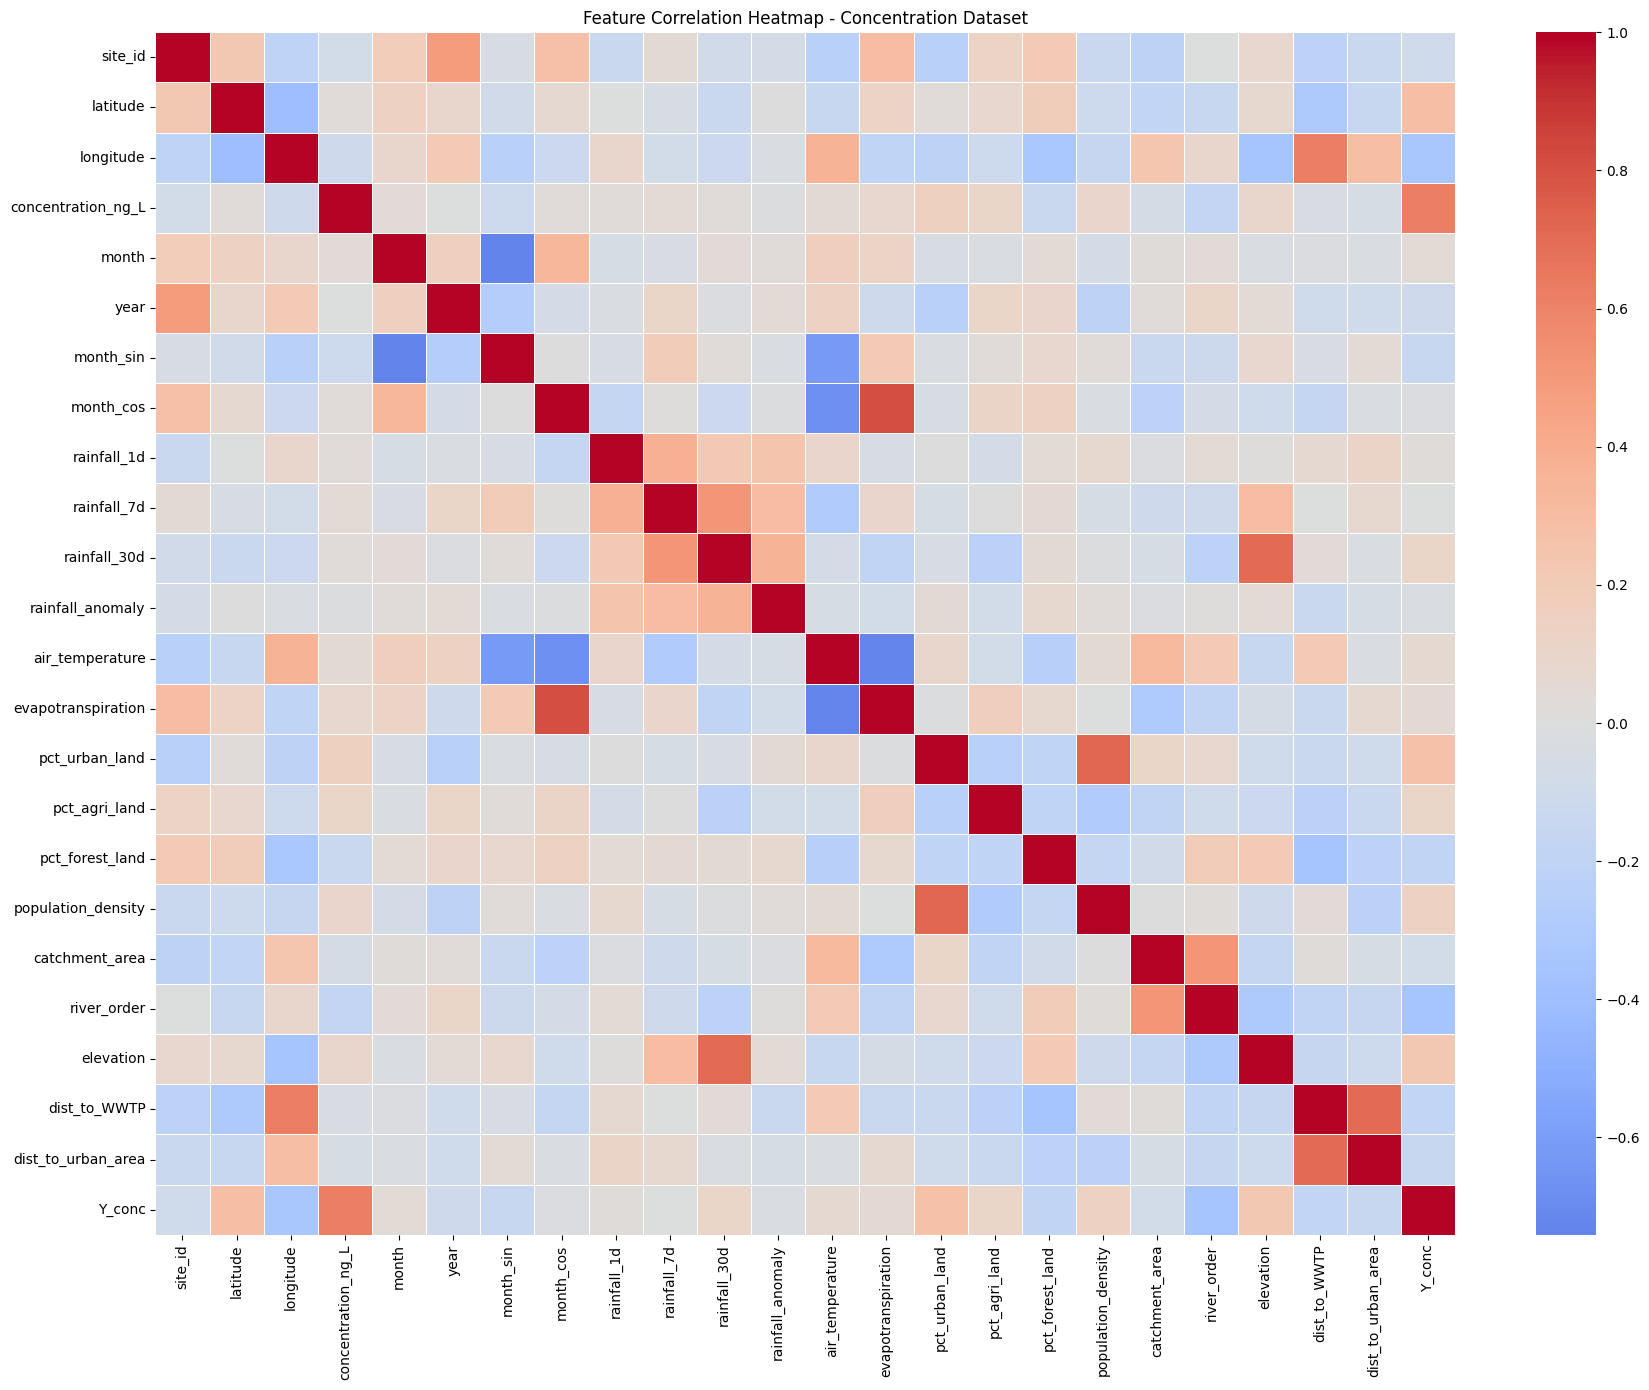

In [17]:
# Select numerical columns
numeric_conc = df_conc.select_dtypes(include='number')

# Correlation matrix
corr_conc = numeric_conc.corr()

# Plot
plt.figure(figsize=(18, 14))

sns.heatmap(
    corr_conc,
    cmap='coolwarm',
    center=0,
    annot=False,
    linewidths=0.5
)

plt.title('Feature Correlation Heatmap - Concentration Dataset')
plt.tight_layout()
plt.show()

In [18]:
# Strong feature-feature correlations
corr = df_conc.select_dtypes(include='number').corr()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

strong_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={
        'level_0': 'Feature 1',
        'level_1': 'Feature 2',
        0: 'Correlation'
    })
)

strong_pairs['Abs_Correlation'] = strong_pairs['Correlation'].abs()

strong_pairs = strong_pairs.sort_values(
    'Abs_Correlation',
    ascending=False
)

print(strong_pairs[strong_pairs['Abs_Correlation'] >= 0.7])

           Feature 1           Feature 2  Correlation  Abs_Correlation
145        month_cos  evapotranspiration     0.815745         0.815745
87             month           month_sin    -0.740713         0.740713
210  air_temperature  evapotranspiration    -0.731243         0.731243
233   pct_urban_land  population_density     0.714492         0.714492
273     dist_to_WWTP  dist_to_urban_area     0.706929         0.706929
194     rainfall_30d           elevation     0.706670         0.706670


In [19]:
!pip install -q optuna imbalanced-learn xgboost catboost statsmodels interpret

ERROR: Could not find a version that satisfies the requirement interpret (from versions: none)
ERROR: No matching distribution found for interpret


# Applying paper Sections 3.6 – 3.13 to the SMX notebook

**Important fix first.** The previous modelling cells fed `concentration_ng_L`, `detection_status`, `LoD`, `LoQ` and `sampling_date` into the occurrence model. `Y_occ` is derived directly from `detection_status`, so those columns *are* the answer. This is why the SMOTE model scored 1.000 on everything. All of them (and `Y_det`) are removed in Section 3.6, and the random stratified split is replaced by the grouped (country-level) split required by Section 3.11.

Everything below follows the paper:

| Section | What is implemented |
|---|---|
| 3.6 | Dataset A (occurrence) and Dataset B (log10(C+1), quantified only) |
| 3.7 | Baselines: logistic regression, GAM-style spline logistic, linear regression, Tobit, mixed-effects |
| 3.8 | RF, XGBoost, CatBoost, SVM/SVR, EBM |
| 3.9 | Class weights, SMOTE sensitivity (training data only), PR-AUC, validation-set threshold |
| 3.10 | Optuna search (paper ranges), validation PR-AUC / RMSE |
| 3.11 | Grouped 70/15/15 split, leave-one-country-out, temporal, water-matrix transfer |
| 3.12 | Full metric set, calibration slope and plot, ng/L back-transformed errors |
| 3.13 | Quantile regression + conformal intervals, calibrated probabilities, uncertainty categories |

In [20]:
import warnings, re
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import optimize, stats

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, SplineTransformer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.svm import SVC, SVR
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix,
    mean_absolute_error, mean_squared_error, r2_score
)

from xgboost import XGBClassifier, XGBRegressor
from catboost import CatBoostClassifier, CatBoostRegressor
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import optuna

try:
    import statsmodels.api as sm
    HAS_SM = True
except ImportError:
    HAS_SM = False
try:
    from interpret.glassbox import ExplainableBoostingClassifier
    HAS_EBM = True
except Exception:
    HAS_EBM = False
print('statsmodels:', HAS_SM, '| interpret (EBM):', HAS_EBM)

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_style('whitegrid')

# ------------------------------- CONFIG -------------------------------------
RANDOM_STATE        = 42
N_TRIALS            = 50      # paper: 50-100 per model. Use 10 for a quick dry run.
N_JOBS              = -1
MIN_COUNTRY_N       = 25      # LOCO: minimum rows for a country to be held out
MIN_MATRIX_N        = 50      # matrix-transfer: minimum rows for a held-out matrix
INCLUDE_COUNTRY     = False   # country one-hot cannot transfer to unseen countries
INCLUDE_COORDS      = False   # lat/lon act as country/site identifiers
THRESHOLD_CRITERION = 'balanced_accuracy'   # or 'f1'
CALIBRATION         = 'isotonic'            # or 'platt'
LOCO_MODELS         = ['Logistic Regression', 'Random Forest', 'XGBoost', 'CatBoost']

statsmodels: True | interpret (EBM): False


## 3.6 Construction of modelling datasets

* **Dataset A (occurrence):** one row per sample, target `Y_occ`.
* **Dataset B (conditional concentration):** quantified samples only, target `Y_conc = log10(C + 1)`.

Columns removed from the feature matrices: target-derived or method-dependent columns (`Y_occ`, `Y_det`, `Y_conc`, `concentration_ng_L`, `detection_status`, `LoD`, `LoQ`), identifiers (`site_id`, `sampling_date`) and, by default, `country` and coordinates (they identify the group being held out in Section 3.11). The water-quality columns were already dropped earlier because they are 85–100 % missing.

In [21]:
df_occ  = df_occ.reset_index(drop=True)
df_conc = df_conc.reset_index(drop=True)

# How is Y_occ defined? (below-LoQ detections are labelled 0 if this shows them under Y_occ = 0)
print(pd.crosstab(df_occ['detection_status'], df_occ['Y_occ']))
print('\nY_conc == log10(C+1)?', np.allclose(df_conc['Y_conc'], np.log10(df_conc['concentration_ng_L'] + 1)))

LEAKY_OR_ID = ['Y_occ', 'Y_det', 'Y_conc', 'site_id', 'sampling_date',
               'concentration_ng_L', 'detection_status', 'LoD', 'LoQ']
extra_drop = []
if not INCLUDE_COUNTRY: extra_drop.append('country')
if not INCLUDE_COORDS:  extra_drop += ['latitude', 'longitude']

XA_full = df_occ.drop(columns=LEAKY_OR_ID + extra_drop, errors='ignore')
XB_full = df_conc.drop(columns=LEAKY_OR_ID + extra_drop, errors='ignore')
FEATURES = [c for c in XA_full.columns if c in XB_full.columns]   # same feature set for A and B

X_occ,  y_occ  = XA_full[FEATURES].copy(), df_occ['Y_occ'].astype(int)
X_conc, y_conc = XB_full[FEATURES].copy(), df_conc['Y_conc'].astype(float)

print(f'\nDataset A: {X_occ.shape}, prevalence of Y_occ = {y_occ.mean():.3f}')
print(f'Dataset B: {X_conc.shape}, Y_conc mean = {y_conc.mean():.3f}')
print('Features:', FEATURES)

# Leakage guard: no single feature should separate the classes almost perfectly
def univariate_auc_scan(X, y, top=8):
    rows = []
    for c in X.select_dtypes(include=np.number).columns:
        m = X[c].notna()
        if m.sum() > 20 and y[m].nunique() == 2:
            a = roc_auc_score(y[m], X.loc[m, c])
            rows.append((c, max(a, 1 - a)))
    return (pd.DataFrame(rows, columns=['feature', 'AUC (best direction)'])
            .sort_values('AUC (best direction)', ascending=False).head(top))
print('\nTop single-feature AUCs (anything above ~0.9 would signal leakage):')
print(univariate_auc_scan(X_occ, y_occ).round(3).to_string(index=False))

Y_occ                 0    1
detection_status            
detected_below_loq  192    0
non_detect          439    0
quantified            0  871

Y_conc == log10(C+1)? True

Dataset A: (1502, 21), prevalence of Y_occ = 0.580
Dataset B: (871, 21), Y_conc mean = 1.163
Features: ['water_matrix', 'month', 'year', 'season', 'month_sin', 'month_cos', 'rainfall_1d', 'rainfall_7d', 'rainfall_30d', 'rainfall_anomaly', 'air_temperature', 'evapotranspiration', 'pct_urban_land', 'pct_agri_land', 'pct_forest_land', 'population_density', 'catchment_area', 'river_order', 'elevation', 'dist_to_WWTP', 'dist_to_urban_area']

Top single-feature AUCs (anything above ~0.9 would signal leakage):
           feature  AUC (best direction)
    catchment_area                 0.636
       river_order                 0.632
   pct_forest_land                 0.620
      dist_to_WWTP                 0.591
         elevation                 0.560
dist_to_urban_area                 0.546
       rainfall_7d            

### Shared utilities (preprocessing, model factory, metrics, threshold selection)
The metric definitions here are the Section 3.12 formulas; the formal reporting tables are in 3.12.

In [22]:
cat_cols = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(X_occ[c])]
num_cols = [c for c in FEATURES if c not in cat_cols]
print('categorical:', cat_cols, '\nnumeric:', len(num_cols))

def make_prep(scale=False, spline=False):
    num_steps = [('imp', SimpleImputer(strategy='median'))]
    if spline: num_steps.append(('spline', SplineTransformer(n_knots=5, degree=3, extrapolation='constant')))
    if scale:  num_steps.append(('sc', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(num_steps), num_cols),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols),
    ])

SCALED = {'Logistic Regression', 'GAM (spline logistic)', 'SVM', 'SVR', 'Linear Regression'}

DEFAULT_PARAMS = {
    ('cls', 'Random Forest'): dict(n_estimators=500, max_depth=8, min_samples_leaf=5),
    ('cls', 'XGBoost'):       dict(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8),
    ('cls', 'CatBoost'):      dict(iterations=500, depth=6, learning_rate=0.05, l2_leaf_reg=5),
    ('cls', 'SVM'):           dict(C=1.0, gamma=0.01),
    ('cls', 'EBM'):           dict(),
    ('reg', 'Random Forest'): dict(n_estimators=500, max_depth=8, min_samples_leaf=5),
    ('reg', 'XGBoost'):       dict(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8),
    ('reg', 'CatBoost'):      dict(iterations=500, depth=6, learning_rate=0.05, l2_leaf_reg=5),
    ('reg', 'SVR'):           dict(C=1.0, gamma=0.01, epsilon=0.1),
}
BEST = dict(DEFAULT_PARAMS)          # overwritten by Optuna in Section 3.10
def params_for(task, name): return BEST.get((task, name), {})

def make_estimator(name, task, params=None, y_train=None, svm_probability=True):
    p = dict(params or {})
    if task == 'cls':
        if name in ('Logistic Regression', 'GAM (spline logistic)'):
            return LogisticRegression(max_iter=5000, class_weight='balanced',
                                      C=p.pop('C', 1.0 if name == 'Logistic Regression' else 0.3), **p)
        if name == 'Random Forest':
            return RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=N_JOBS, **p)
        if name == 'XGBoost':
            if y_train is None:
                raise ValueError("XGBoost classifier needs y_train to set scale_pos_weight (y=None would give 0)")
            spw = (np.asarray(y_train) == 0).sum() / max((np.asarray(y_train) == 1).sum(), 1)
            assert spw > 0, 'y_train must contain both classes'
            return XGBClassifier(scale_pos_weight=spw, eval_metric='logloss', colsample_bytree=0.8,
                                 random_state=RANDOM_STATE, n_jobs=N_JOBS, **p)
        if name == 'CatBoost':
            return CatBoostClassifier(loss_function='Logloss', auto_class_weights='Balanced', verbose=False,
                                      random_seed=RANDOM_STATE, allow_writing_files=False, thread_count=-1, **p)
        if name == 'SVM':
            return SVC(kernel='rbf', class_weight='balanced', probability=svm_probability,
                       random_state=RANDOM_STATE, **p)
        if name == 'EBM':
            return ExplainableBoostingClassifier(random_state=RANDOM_STATE, **p)
    else:
        if name == 'Linear Regression': return LinearRegression(**p)
        if name == 'Random Forest':
            return RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS, **p)
        if name == 'XGBoost':
            return XGBRegressor(objective='reg:squarederror', colsample_bytree=0.8,
                                random_state=RANDOM_STATE, n_jobs=N_JOBS, **p)
        if name == 'CatBoost':
            return CatBoostRegressor(loss_function='RMSE', verbose=False, random_seed=RANDOM_STATE,
                                     allow_writing_files=False, thread_count=-1, **p)
        if name == 'SVR': return SVR(kernel='rbf', **p)
    raise ValueError(f'unknown model {name} / {task}')

def make_pipe(name, task, params=None, y_train=None, svm_probability=True):
    prep = make_prep(scale=name in SCALED, spline=(name == 'GAM (spline logistic)'))
    return Pipeline([('prep', prep),
                     ('model', make_estimator(name, task, params, y_train, svm_probability))])

def predict_cls(pipe, X): return pipe.predict_proba(X)[:, 1]
def predict_reg(pipe, X): return np.clip(pipe.predict(X), 0, None)    # log10(C+1) >= 0

# ------------------------------ metrics (3.12) -------------------------------
def calibration_slope(y, p, eps=1e-6):
    p = np.clip(np.asarray(p, float), eps, 1 - eps)
    z = np.log(p / (1 - p)).reshape(-1, 1)
    lr = LogisticRegression(C=1e6, max_iter=2000).fit(z, y)
    return float(lr.coef_[0][0]), float(lr.intercept_[0])

def expected_calibration_error(y, p, n_bins=10):
    y, p = np.asarray(y), np.asarray(p)
    idx = np.clip(np.digitize(p, np.linspace(0, 1, n_bins + 1)) - 1, 0, n_bins - 1)
    return float(sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean())
                     for b in range(n_bins) if (idx == b).any()))

def classification_metrics(y_true, prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(int); prob = np.asarray(prob, float)
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y_true)) == 2
    return {
        'Accuracy': accuracy_score(y_true, pred),
        'Balanced Accuracy': balanced_accuracy_score(y_true, pred) if both else np.nan,
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall': recall_score(y_true, pred, zero_division=0),
        'F1': f1_score(y_true, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, prob) if both else np.nan,
        'PR-AUC': average_precision_score(y_true, prob) if both else np.nan,
        'Brier': brier_score_loss(y_true, prob),
        'Cal. slope': calibration_slope(y_true, prob)[0] if both else np.nan,
        'ECE': expected_calibration_error(y_true, prob),
        'Threshold': threshold, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    }

def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    err = y_pred - y_true
    c_true = 10 ** y_true - 1
    c_pred = 10 ** np.clip(y_pred, 0, None) - 1          # back-transform to ng/L
    return {
        'RMSE': float(np.sqrt(np.mean(err ** 2))), 'MAE': float(np.mean(np.abs(err))),
        'R2': r2_score(y_true, y_pred), 'Bias (log10)': float(err.mean()),
        'RMSE (ng/L)': float(np.sqrt(np.mean((c_pred - c_true) ** 2))),
        'MAE (ng/L)': float(np.mean(np.abs(c_pred - c_true))),
        'Bias (ng/L)': float(np.mean(c_pred - c_true)),
        'Median abs. error (ng/L)': float(np.median(np.abs(c_pred - c_true))),
    }

# ---------------------- threshold selection (3.9) ----------------------------
def select_threshold(y_true, prob, criterion='balanced_accuracy', grid=None):
    grid = np.arange(0.05, 0.951, 0.01) if grid is None else grid
    y_true = np.asarray(y_true).astype(int); prob = np.asarray(prob, float)
    scores = np.array([
        balanced_accuracy_score(y_true, (prob >= t).astype(int)) if criterion == 'balanced_accuracy'
        else f1_score(y_true, (prob >= t).astype(int), zero_division=0) for t in grid])
    return float(np.median(grid[scores >= scores.max() - 1e-9]))   # middle of the best plateau

categorical: ['water_matrix', 'season'] 
numeric: 19


## 3.11 (setup) Validation 1: grouped spatial split — 70 % / 15 % / 15 % of countries

All rows of a country stay together. Among many random country assignments, the one is chosen whose **row fractions are closest to 70/15/15 and whose positive-class prevalence is most similar across splits** (this avoids the problem of a validation set with a very different prevalence from the test set, which distorts threshold selection). The same country assignment is used for Dataset B.

In [23]:
def grouped_split(groups, y, fractions=(0.70, 0.15, 0.15), n_tries=5000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    groups = np.asarray(groups); y = np.asarray(y)
    ctry = pd.unique(groups); n = len(ctry)
    n_tr, n_va = int(round(fractions[0] * n)), int(round(fractions[1] * n))
    cnt = pd.Series(groups).value_counts()
    pos = pd.Series(y).groupby(groups).sum()
    best = None
    for _ in range(n_tries):
        perm = rng.permutation(ctry)
        parts = (perm[:n_tr], perm[n_tr:n_tr + n_va], perm[n_tr + n_va:])
        if any(len(p) == 0 for p in parts): continue
        rows = [cnt[list(p)].sum() / len(groups) for p in parts]
        prev = [pos[list(p)].sum() / cnt[list(p)].sum() for p in parts]
        cost = sum(abs(r - f) for r, f in zip(rows, fractions)) + 0.5 * (max(prev) - min(prev))
        if best is None or cost < best[0]: best = (cost, parts)
    return {'train': list(best[1][0]), 'val': list(best[1][1]), 'test': list(best[1][2])}

SPLIT_COUNTRIES = grouped_split(df_occ['country'], y_occ)
ctry2split = {c: s for s, cs in SPLIT_COUNTRIES.items() for c in cs}

mask_A = {s: (df_occ['country'].map(ctry2split) == s).values for s in ('train', 'val', 'test')}
mask_B = {s: (df_conc['country'].map(ctry2split) == s).values for s in ('train', 'val', 'test')}
assert df_conc['country'].map(ctry2split).notna().all(), 'a Dataset-B country is missing from Dataset A'

XA_tr, yA_tr = X_occ.loc[mask_A['train']], y_occ.loc[mask_A['train']]
XA_va, yA_va = X_occ.loc[mask_A['val']],   y_occ.loc[mask_A['val']]
XA_te, yA_te = X_occ.loc[mask_A['test']],  y_occ.loc[mask_A['test']]
XB_tr, yB_tr = X_conc.loc[mask_B['train']], y_conc.loc[mask_B['train']]
XB_va, yB_va = X_conc.loc[mask_B['val']],   y_conc.loc[mask_B['val']]
XB_te, yB_te = X_conc.loc[mask_B['test']],  y_conc.loc[mask_B['test']]

summary = pd.DataFrame({
    s: {'countries': len(SPLIT_COUNTRIES[s]), 'rows A': int(mask_A[s].sum()),
        'prevalence A': round(float(y_occ[mask_A[s]].mean()), 3), 'rows B': int(mask_B[s].sum()),
        'mean Y_conc B': round(float(y_conc[mask_B[s]].mean()), 3)}
    for s in ('train', 'val', 'test')}).T
print(summary)
for s in ('val', 'test'): print(f'{s} countries:', SPLIT_COUNTRIES[s])

# Registries that collect predictions for the reporting sections (3.12)
CLS, REG = {}, {}
def register_cls(name, p_val, p_test):
    CLS[name] = {'val': np.asarray(p_val, float), 'test': np.asarray(p_test, float),
                 'tau': select_threshold(yA_va, p_val, THRESHOLD_CRITERION)}
def register_reg(name, pred_val, pred_test):
    REG[name] = {'val': np.clip(np.asarray(pred_val, float), 0, None),
                 'test': np.clip(np.asarray(pred_test, float), 0, None)}
def tau_for(m): return CLS.get(f'{m} (tuned)', CLS.get(m))['tau']

       countries  rows A  prevalence A  rows B  mean Y_conc B
train       19.0  1039.0         0.578   601.0          1.233
val          4.0   240.0         0.525   126.0          1.104
test         4.0   223.0         0.646   144.0          0.923
val countries: ['Czech Republic', 'Greece', 'Austria', 'Ukraine']
test countries: ['Switzerland', 'Georgia', 'Croatia', 'Portugal']


## 3.7 Baseline statistical models

Logistic regression, a GAM-style additive model (spline-expanded logistic regression — equivalent to a penalised GAM; swap in `pygam` if you prefer), linear regression, Tobit regression (using all occurrence rows, with non-quantified samples left-censored at the LoQ), and a mixed-effects model with a country random intercept (predictions for unseen countries use the fixed effects only, which is what a new region would get).

In [24]:
# ---- occurrence baselines
for name in ['Logistic Regression', 'GAM (spline logistic)']:
    pipe = make_pipe(name, 'cls', {}, yA_tr).fit(XA_tr, yA_tr)
    register_cls(name, predict_cls(pipe, XA_va), predict_cls(pipe, XA_te))

# ---- concentration baseline: linear regression on log10(C+1)
pipe = make_pipe('Linear Regression', 'reg').fit(XB_tr, yB_tr)
register_reg('Linear Regression', predict_reg(pipe, XB_va), predict_reg(pipe, XB_te))

# ---- Tobit (left-censored normal regression), trained on ALL occurrence rows of the training countries
def fit_tobit(Z, y_obs, cens, c_pt, l2=1e-2):
    n, p = Z.shape
    A = np.hstack([np.ones((n, 1)), Z])
    ols = np.linalg.lstsq(A[~cens], y_obs[~cens], rcond=None)[0]
    s0 = np.std(y_obs[~cens] - A[~cens] @ ols) + 1e-6
    def nll(theta):
        beta, log_s = theta[:-1], theta[-1]; s = np.exp(log_s)
        mu = A @ beta
        ll = stats.norm.logpdf((y_obs[~cens] - mu[~cens]) / s).sum() - (~cens).sum() * log_s
        ll += stats.norm.logcdf((c_pt[cens] - mu[cens]) / s).sum()
        return -ll + l2 * np.sum(beta[1:] ** 2)
    res = optimize.minimize(nll, np.r_[ols, np.log(s0)], method='L-BFGS-B', options={'maxiter': 500})
    return {'beta': res.x[:-1], 'sigma': float(np.exp(res.x[-1])), 'converged': bool(res.success)}

def tobit_predict(m, Z, c0=None):
    mu = m['beta'][0] + Z @ m['beta'][1:]
    if c0 is None: return mu                                   # latent mean
    s = m['sigma']; a = (c0 - mu) / s                          # E[y | y > c0]
    return mu + s * stats.norm.pdf(a) / np.clip(stats.norm.sf(a), 1e-9, None)

occ_tr = df_occ.loc[mask_A['train']]
cens = (occ_tr['detection_status'] != 'quantified').values
c_pt = np.log10(occ_tr['LoQ'].values + 1)
y_obs = np.where(cens, c_pt, np.log10(occ_tr['concentration_ng_L'].values + 1))
prep_t = make_prep(scale=True).fit(XA_tr)
tobit = fit_tobit(prep_t.transform(XA_tr), y_obs, cens, c_pt)
c0 = float(np.median(c_pt[cens])) if cens.any() else 0.0
print(f"Tobit: converged={tobit['converged']}, sigma={tobit['sigma']:.3f}, censored share={cens.mean():.2f}")
Zva, Zte = prep_t.transform(XB_va), prep_t.transform(XB_te)
register_reg('Tobit (latent mean)', tobit_predict(tobit, Zva), tobit_predict(tobit, Zte))
register_reg('Tobit (E[y | quantified])', tobit_predict(tobit, Zva, c0), tobit_predict(tobit, Zte, c0))

# ---- mixed-effects model with country random intercept (Dataset B)
if HAS_SM:
    try:
        prep_me = make_prep(scale=True).fit(XB_tr)
        names = list(prep_me.get_feature_names_out())
        def me_design(X, keep=None):
            D = pd.DataFrame(prep_me.transform(X), columns=names)
            if keep is None:
                keep = [c for c in D.columns if D[c].std() > 1e-8]
                for c in cat_cols:                                 # drop one reference level per categorical
                    lv = [n for n in keep if n.startswith(f'cat__{c}_')]
                    if lv: keep.remove(lv[0])
            return sm.add_constant(D[keep], has_constant='add'), keep
        A_tr, keep_me = me_design(XB_tr)
        mres = sm.MixedLM(endog=yB_tr.values, exog=A_tr.values,
                          groups=df_conc.loc[mask_B['train'], 'country'].values).fit(method=['lbfgs'], reml=True)
        beta_me = np.asarray(mres.fe_params, float)
        re_var = float(np.asarray(mres.cov_re).ravel()[0])          # FIX: cov_re is an ndarray here, not a DataFrame (.iloc crashed)
        if (not mres.converged) or (not np.isfinite(beta_me).all()) or re_var < 1e-8:
            # random-intercept variance collapsed to 0 / optimiser failed -> fixed effects are unreliable; use the OLS fit
            beta_me = np.asarray(sm.OLS(yB_tr.values, A_tr.values).fit().params, float)
            print('Mixed-effects: boundary/non-converged fit -> fixed effects taken from OLS')
        register_reg('Mixed-effects (country RE)',
                     me_design(XB_va, keep_me)[0].values @ beta_me, me_design(XB_te, keep_me)[0].values @ beta_me)
        print('Mixed-effects: converged =', mres.converged, '| country variance =', re_var)
    except Exception as e:
        print('Mixed-effects model skipped:', repr(e))
else:
    print('statsmodels not available: mixed-effects baseline skipped')

print('\nBaselines, validation set (PR-AUC / RMSE):')
for k, r in CLS.items(): print(f"  {k:28s} PR-AUC={average_precision_score(yA_va, r['val']):.3f}")
for k, r in REG.items(): print(f"  {k:28s} RMSE  ={np.sqrt(mean_squared_error(yB_va, r['val'])):.3f}")

Tobit: converged=True, sigma=0.844, censored share=0.42
Mixed-effects: boundary/non-converged fit -> fixed effects taken from OLS
Mixed-effects: converged = True | country variance = 0.0

Baselines, validation set (PR-AUC / RMSE):
  Logistic Regression          PR-AUC=0.709
  GAM (spline logistic)        PR-AUC=0.701
  Linear Regression            RMSE  =0.630
  Tobit (latent mean)          RMSE  =0.840
  Tobit (E[y | quantified])    RMSE  =0.671
  Mixed-effects (country RE)   RMSE  =0.630


/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/usr/local/lib/python3.13/dist-packages/statsmodels/regression/mixed_linear_model.py:2429: SingularMatrixWarning: The random effects covariance matrix is singular.
  scale = self.get_scale(fe_params, cov_re_unscaled, vcomp_unscaled)
/tmp/ipykernel_49/2748315090.py:58: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  groups=df_conc.loc[mask_B['train'], 'country'].values).fit(method=['lbfgs'], reml=True)
/tmp/ipykernel_49/2748315090.py:58: SingularMatrixWarning: The random effects covariance matrix is singular.
  groups=df_conc.loc[mask_B['train'], 'country'].values).fit(method=['lbfgs'], reml=True)
/tmp/ipykernel_49/2748315090.py:58: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  groups=df_conc.loc[mask_B['train'], 'country'].values).

## 3.8 Machine-learning models

Random forest, XGBoost, CatBoost, SVM/SVR and the explainable boosting machine (EBM), trained here with regularised default settings; they are tuned in 3.10. XGBoost and CatBoost are the primary models. TabNet/MLP is **not** run: with ~1,500 occurrence rows and ~870 concentration rows the dataset is not large enough to justify it (the paper's own condition), and an LSTM is not appropriate for independent, irregular monitoring records.

In [25]:
CLS_MODELS = ['Random Forest', 'XGBoost', 'CatBoost', 'SVM'] + (['EBM'] if HAS_EBM else [])
REG_MODELS = ['Random Forest', 'XGBoost', 'CatBoost', 'SVR']

for name in CLS_MODELS:
    pipe = make_pipe(name, 'cls', params_for('cls', name), yA_tr).fit(XA_tr, yA_tr)
    register_cls(f'{name} (default)', predict_cls(pipe, XA_va), predict_cls(pipe, XA_te))
for name in REG_MODELS:
    pipe = make_pipe(name, 'reg', params_for('reg', name)).fit(XB_tr, yB_tr)
    register_reg(f'{name} (default)', predict_reg(pipe, XB_va), predict_reg(pipe, XB_te))

print('Default models, validation set:')
for k, r in CLS.items():
    if 'default' in k: print(f"  {k:28s} PR-AUC={average_precision_score(yA_va, r['val']):.3f}  ROC-AUC={roc_auc_score(yA_va, r['val']):.3f}")
for k, r in REG.items():
    if 'default' in k: print(f"  {k:28s} RMSE ={np.sqrt(mean_squared_error(yB_va, r['val'])):.3f}")

Default models, validation set:
  Random Forest (default)      PR-AUC=0.755  ROC-AUC=0.694
  XGBoost (default)            PR-AUC=0.764  ROC-AUC=0.715
  CatBoost (default)           PR-AUC=0.754  ROC-AUC=0.695
  SVM (default)                PR-AUC=0.714  ROC-AUC=0.666
  Random Forest (default)      RMSE =0.805
  XGBoost (default)            RMSE =0.880
  CatBoost (default)           RMSE =0.782
  SVR (default)                RMSE =0.854


## 3.9 Imbalanced-data handling

* Class-weighted loss: `class_weight='balanced'` (LR, RF, SVM), `scale_pos_weight` (XGBoost), `auto_class_weights='Balanced'` (CatBoost) — already used above.
* SMOTE: **sensitivity analysis only**, applied inside the training data (it sits inside the pipeline, so validation/test rows are never oversampled). Note SMOTE interpolates the one-hot columns, which is why it is not the primary strategy.
* PR-AUC reported alongside ROC-AUC, plus balanced accuracy, precision, recall, F1.
* The threshold τ is chosen on the **validation set** (balanced accuracy by default, set `THRESHOLD_CRITERION='f1'` to change), never fixed at 0.50.

Class weights vs SMOTE (test set, validation-selected tau):
                               Balanced Accuracy  Precision  Recall     F1  \
Model                                                                        
XGBoost (default)                          0.708      0.820   0.694  0.752   
XGBoost + SMOTE (sensitivity)              0.732      0.895   0.590  0.711   

                               ROC-AUC  PR-AUC  Threshold  
Model                                                      
XGBoost (default)                0.790   0.887       0.40  
XGBoost + SMOTE (sensitivity)    0.769   0.877       0.49  

Threshold effect, XGBoost (default), test set:
                                  Accuracy  Balanced Accuracy  Precision  \
tau = 0.50                           0.722              0.748       0.88   
tau = 0.40 (validation-selected)     0.704              0.708       0.82   

                                  Recall     F1  
tau = 0.50                         0.660  0.754  
tau = 0.40

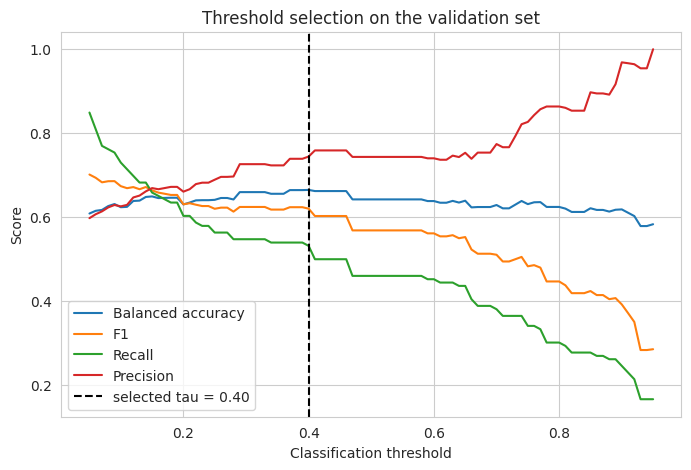

In [26]:
smote_pipe = ImbPipeline([
    ('prep', make_prep(scale=False)),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('model', XGBClassifier(eval_metric='logloss', colsample_bytree=0.8, random_state=RANDOM_STATE,
                            n_jobs=N_JOBS, **DEFAULT_PARAMS[('cls', 'XGBoost')])),
]).fit(XA_tr, yA_tr)
register_cls('XGBoost + SMOTE (sensitivity)', predict_cls(smote_pipe, XA_va), predict_cls(smote_pipe, XA_te))

rows = []
for k in ['XGBoost (default)', 'XGBoost + SMOTE (sensitivity)']:
    r = CLS[k]
    m = classification_metrics(yA_te, r['test'], r['tau']); m['Model'] = k
    rows.append(m)
print('Class weights vs SMOTE (test set, validation-selected tau):')
print(pd.DataFrame(rows).set_index('Model')[['Balanced Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC', 'Threshold']].round(3))

# Why a fixed 0.50 threshold is not used: effect on the primary model (test set)
r = CLS['XGBoost (default)']
cmp = pd.DataFrame({f'tau = 0.50': classification_metrics(yA_te, r['test'], 0.5),
                    f"tau = {r['tau']:.2f} (validation-selected)": classification_metrics(yA_te, r['test'], r['tau'])}).T
print('\nThreshold effect, XGBoost (default), test set:')
print(cmp[['Accuracy', 'Balanced Accuracy', 'Precision', 'Recall', 'F1']].round(3))

# Threshold curve on the validation set
grid = np.arange(0.05, 0.951, 0.01)
pv = r['val']
curves = pd.DataFrame({'threshold': grid,
    'Balanced accuracy': [balanced_accuracy_score(yA_va, (pv >= t).astype(int)) for t in grid],
    'F1':                [f1_score(yA_va, (pv >= t).astype(int), zero_division=0) for t in grid],
    'Recall':            [recall_score(yA_va, (pv >= t).astype(int), zero_division=0) for t in grid],
    'Precision':         [precision_score(yA_va, (pv >= t).astype(int), zero_division=0) for t in grid]})
plt.figure(figsize=(8, 5))
for c in curves.columns[1:]: plt.plot(curves['threshold'], curves[c], label=c)
plt.axvline(r['tau'], color='k', ls='--', label=f"selected tau = {r['tau']:.2f}")
plt.xlabel('Classification threshold'); plt.ylabel('Score'); plt.title('Threshold selection on the validation set')
plt.legend(); plt.show()

## 3.10 Hyperparameter optimisation (Optuna)

Search ranges are the ones in the paper. Each trial trains on the **training countries** and is scored on the **validation countries**: PR-AUC for classification (maximise), RMSE for regression (minimise). `N_TRIALS` is set in the config cell (paper: 50–100). CatBoost with depth 10 / 1,000 iterations is the slow part: set `N_TRIALS = 10` for a dry run.

In [27]:
def sug_int(t, n, lo, hi, step=1): return t.suggest_int(n, lo, hi, step=step)

SEARCH = {
    'Random Forest': lambda t: dict(n_estimators=sug_int(t, 'n_estimators', 300, 1000, 100),
                                    max_depth=sug_int(t, 'max_depth', 5, 30),
                                    min_samples_leaf=sug_int(t, 'min_samples_leaf', 1, 20)),
    'XGBoost':       lambda t: dict(n_estimators=sug_int(t, 'n_estimators', 200, 1000, 100),
                                    max_depth=sug_int(t, 'max_depth', 3, 10),
                                    learning_rate=t.suggest_float('learning_rate', 0.01, 0.10, log=True),
                                    subsample=t.suggest_float('subsample', 0.6, 1.0)),
    'CatBoost':      lambda t: dict(iterations=sug_int(t, 'iterations', 200, 1000, 100),
                                    depth=sug_int(t, 'depth', 4, 10),
                                    learning_rate=t.suggest_float('learning_rate', 0.01, 0.10, log=True),
                                    l2_leaf_reg=t.suggest_float('l2_leaf_reg', 1, 20)),
    'SVM':           lambda t: dict(C=t.suggest_float('C', 0.1, 100, log=True),
                                    gamma=t.suggest_float('gamma', 1e-4, 1e-1, log=True)),
    'SVR':           lambda t: dict(C=t.suggest_float('C', 0.1, 100, log=True),
                                    gamma=t.suggest_float('gamma', 1e-4, 1e-1, log=True),
                                    epsilon=t.suggest_float('epsilon', 0.01, 0.50)),
}

def tune(task, name, n_trials=N_TRIALS):
    Xtr, ytr, Xva, yva = (XA_tr, yA_tr, XA_va, yA_va) if task == 'cls' else (XB_tr, yB_tr, XB_va, yB_va)
    def objective(trial):
        params = SEARCH[name](trial)
        pipe = make_pipe(name, task, params, ytr, svm_probability=False).fit(Xtr, ytr)
        if task == 'cls':
            s = pipe.decision_function(Xva) if name == 'SVM' else pipe.predict_proba(Xva)[:, 1]
            return average_precision_score(yva, s)
        return float(np.sqrt(mean_squared_error(yva, pipe.predict(Xva))))
    study = optuna.create_study(direction='maximize' if task == 'cls' else 'minimize',
                                sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=n_trials)
    return study

TUNING_LOG = []
for task, names in [('cls', ['Random Forest', 'XGBoost', 'CatBoost', 'SVM']),
                    ('reg', ['Random Forest', 'XGBoost', 'CatBoost', 'SVR'])]:
    for name in names:
        study = tune(task, name)
        BEST[(task, name)] = dict(study.best_params)
        TUNING_LOG.append({'task': task, 'model': name, 'best val score': round(study.best_value, 4),
                           'metric': 'PR-AUC' if task == 'cls' else 'RMSE', 'params': dict(study.best_params)})
        print(f'{task} {name}: {study.best_value:.4f}  {study.best_params}')

# Refit the tuned models on the training countries and register them
for name in ['Random Forest', 'XGBoost', 'CatBoost', 'SVM']:
    pipe = make_pipe(name, 'cls', params_for('cls', name), yA_tr).fit(XA_tr, yA_tr)
    register_cls(f'{name} (tuned)', predict_cls(pipe, XA_va), predict_cls(pipe, XA_te))
for name in ['Random Forest', 'XGBoost', 'CatBoost', 'SVR']:
    pipe = make_pipe(name, 'reg', params_for('reg', name)).fit(XB_tr, yB_tr)
    register_reg(f'{name} (tuned)', predict_reg(pipe, XB_va), predict_reg(pipe, XB_te))
pd.DataFrame(TUNING_LOG)

cls Random Forest: 0.7773  {'n_estimators': 800, 'max_depth': 25, 'min_samples_leaf': 1}
cls XGBoost: 0.7806  {'n_estimators': 500, 'max_depth': 7, 'learning_rate': 0.012318981236462122, 'subsample': 0.8488704514267207}
cls CatBoost: 0.7731  {'iterations': 600, 'depth': 7, 'learning_rate': 0.042775368977036515, 'l2_leaf_reg': 6.114240917987483}
cls SVM: 0.7201  {'C': 1.3770760227428733, 'gamma': 0.032353502089576366}
reg Random Forest: 0.7968  {'n_estimators': 600, 'max_depth': 25, 'min_samples_leaf': 4}
reg XGBoost: 0.6976  {'n_estimators': 700, 'max_depth': 10, 'learning_rate': 0.024918634987178674, 'subsample': 0.6272278585743689}
reg CatBoost: 0.7056  {'iterations': 200, 'depth': 10, 'learning_rate': 0.01477081357571732, 'l2_leaf_reg': 19.4537272884965}
reg SVR: 0.6914  {'C': 1.7501614465005244, 'gamma': 0.00010679619402873211, 'epsilon': 0.14958458816891618}


,task,model,best val score,metric,params
0,cls,Random Forest,0.7773,PR-AUC,"{'n_estimators': 800, 'max_depth': 25, 'min_sa..."
1,cls,XGBoost,0.7806,PR-AUC,"{'n_estimators': 500, 'max_depth': 7, 'learnin..."
2,cls,CatBoost,0.7731,PR-AUC,"{'iterations': 600, 'depth': 7, 'learning_rate..."
3,cls,SVM,0.7201,PR-AUC,"{'C': 1.3770760227428733, 'gamma': 0.032353502..."
4,reg,Random Forest,0.7968,RMSE,"{'n_estimators': 600, 'max_depth': 25, 'min_sa..."
5,reg,XGBoost,0.6976,RMSE,"{'n_estimators': 700, 'max_depth': 10, 'learni..."
6,reg,CatBoost,0.7056,RMSE,"{'iterations': 200, 'depth': 10, 'learning_rat..."
7,reg,SVR,0.6914,RMSE,"{'C': 1.7501614465005244, 'gamma': 0.000106796..."


## 3.11 Spatial, temporal and external validation

**Validation 1 (grouped 70/15/15 split)** was set up above; its full results are in Section 3.12. Validations 2–4 follow. All of them reuse the tuned hyperparameters and the validation-selected thresholds τ from Validation 1. Note that the hyperparameters were tuned on the Validation-1 validation countries, so those countries are very slightly optimistic when they appear as held-out countries in Validation 2.

Compact view of Validation 1 (test countries):

In [28]:
cols = ['Balanced Accuracy', 'Recall', 'Precision', 'ROC-AUC', 'PR-AUC']
v1 = pd.DataFrame({k: classification_metrics(yA_te, r['test'], r['tau']) for k, r in CLS.items()}).T[cols].astype(float).round(3)
print('Validation 1, occurrence (test countries):'); print(v1.sort_values('PR-AUC', ascending=False))
v1r = pd.DataFrame({k: regression_metrics(yB_te, r['test']) for k, r in REG.items()}).T[['RMSE', 'MAE', 'R2']].astype(float).round(3)
print('\nValidation 1, concentration (test countries):'); print(v1r.sort_values('RMSE'))

Validation 1, occurrence (test countries):
                               Balanced Accuracy  Recall  Precision  ROC-AUC  \
Random Forest (tuned)                      0.709   0.722      0.812    0.813   
Random Forest (default)                    0.716   0.722      0.819    0.808   
XGBoost (tuned)                            0.739   0.681      0.860    0.812   
XGBoost (default)                          0.708   0.694      0.820    0.790   
CatBoost (default)                         0.642   0.840      0.733    0.772   
XGBoost + SMOTE (sensitivity)              0.732   0.590      0.895    0.769   
CatBoost (tuned)                           0.686   0.778      0.778    0.751   
SVM (tuned)                                0.607   0.924      0.704    0.735   
GAM (spline logistic)                      0.724   0.840      0.796    0.788   
SVM (default)                              0.503   0.931      0.647    0.568   
Logistic Regression                        0.430   0.785      0.608    0.469 

### Validation 2: leave-one-country-out (LOCO)
Train on every other country, test on the withheld one, for each country with at least `MIN_COUNTRY_N` rows. Per-country accuracy is dominated by that country's prevalence, so ROC-AUC / PR-AUC and balanced accuracy are the numbers to read.

LOCO, occurrence: pooled over all held-out countries
                     Balanced Accuracy  Recall  Precision  ROC-AUC  PR-AUC  \
Logistic Regression              0.526   0.931      0.597    0.652   0.746   
Random Forest                    0.651   0.822      0.688    0.727   0.787   
XGBoost                          0.646   0.827      0.683    0.725   0.785   
CatBoost                         0.622   0.861      0.661    0.716   0.772   

                     Brier  Cal. slope  
Logistic Regression  0.244       0.311  
Random Forest        0.210       0.675  
XGBoost              0.219       0.484  
CatBoost             0.229       0.379  

LOCO, concentration: pooled over all held-out countries
                    RMSE    MAE     R2  Bias (log10)  MAE (ng/L)
Linear Regression  0.614  0.508  0.231        -0.048      47.223
Random Forest      0.594  0.455  0.279         0.054      45.744
XGBoost            0.589  0.464  0.292         0.052      45.672
CatBoost           0.629  0.516  0

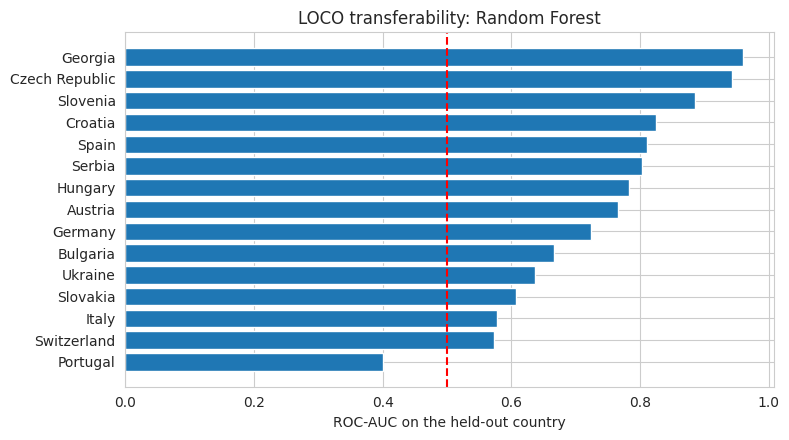

In [29]:
def leave_one_group_out_cls(models, group_series, min_n):
    counts = group_series.value_counts(); eligible = counts[counts >= min_n].index.tolist()
    oof = {m: np.full(len(df_occ), np.nan) for m in models}; rows = []
    for g in eligible:
        te = (group_series == g).values
        for m in models:
            pipe = make_pipe(m, 'cls', params_for('cls', m), y_occ.loc[~te]).fit(X_occ.loc[~te], y_occ.loc[~te])
            oof[m][te] = predict_cls(pipe, X_occ.loc[te])
            r = classification_metrics(y_occ.loc[te], oof[m][te], tau_for(m))
            rows.append({'group': g, 'model': m, 'n': int(te.sum()), 'prevalence': float(y_occ.loc[te].mean()),
                         'ROC-AUC': r['ROC-AUC'], 'PR-AUC': r['PR-AUC'],
                         'Balanced Accuracy': r['Balanced Accuracy'], 'Accuracy': r['Accuracy']})
    return pd.DataFrame(rows), oof

def leave_one_group_out_reg(models, group_series, min_n):
    counts = group_series.value_counts(); eligible = counts[counts >= min_n].index.tolist()
    oof = {m: np.full(len(df_conc), np.nan) for m in models}; rows = []
    for g in eligible:
        te = (group_series == g).values
        for m in models:
            pipe = make_pipe(m, 'reg', params_for('reg', m)).fit(X_conc.loc[~te], y_conc.loc[~te])
            oof[m][te] = predict_reg(pipe, X_conc.loc[te])
            r = regression_metrics(y_conc.loc[te], oof[m][te])
            rows.append({'group': g, 'model': m, 'n': int(te.sum()), 'RMSE': r['RMSE'], 'MAE': r['MAE'],
                         'Bias (log10)': r['Bias (log10)'], 'MAE (ng/L)': r['MAE (ng/L)']})
    return pd.DataFrame(rows), oof

def pooled_cls(oof, models):
    out = {}
    for m in models:
        ok = ~np.isnan(oof[m]); out[m] = classification_metrics(y_occ[ok], oof[m][ok], tau_for(m))
    return pd.DataFrame(out).T[['Balanced Accuracy', 'Recall', 'Precision', 'ROC-AUC', 'PR-AUC', 'Brier', 'Cal. slope']].astype(float).round(3)

def pooled_reg(oof, models):
    out = {}
    for m in models:
        ok = ~np.isnan(oof[m]); out[m] = regression_metrics(y_conc[ok], oof[m][ok])
    return pd.DataFrame(out).T[['RMSE', 'MAE', 'R2', 'Bias (log10)', 'MAE (ng/L)']].astype(float).round(3)

REG_LOCO_MODELS = ['Linear Regression', 'Random Forest', 'XGBoost', 'CatBoost']
loco_cls_df, loco_cls_oof = leave_one_group_out_cls(LOCO_MODELS, df_occ['country'], MIN_COUNTRY_N)
loco_reg_df, loco_reg_oof = leave_one_group_out_reg(REG_LOCO_MODELS, df_conc['country'], MIN_COUNTRY_N)

print('LOCO, occurrence: pooled over all held-out countries'); print(pooled_cls(loco_cls_oof, LOCO_MODELS))
print('\nLOCO, concentration: pooled over all held-out countries'); print(pooled_reg(loco_reg_oof, REG_LOCO_MODELS))

best_m = pooled_cls(loco_cls_oof, LOCO_MODELS)['PR-AUC'].idxmax()
pc = loco_cls_df[loco_cls_df['model'] == best_m].sort_values('ROC-AUC')
print(f'\nPer-country results for {best_m} (worst ROC-AUC first):'); print(pc.round(3).to_string(index=False))
plt.figure(figsize=(8, max(3, 0.3 * len(pc))))
plt.barh(pc['group'].astype(str), pc['ROC-AUC'].fillna(0.5)); plt.axvline(0.5, color='r', ls='--')
plt.xlabel('ROC-AUC on the held-out country'); plt.title(f'LOCO transferability: {best_m}'); plt.tight_layout(); plt.show()

### Validation 3: temporal validation
Earliest 70 % of the records (by `year`) for training, the next 15 % for validation (to choose τ), the most recent 15 % for testing. Years are never split across partitions. Skipped automatically if the records do not span enough years. Country mix also changes over time, so temporal and spatial effects are partly confounded.

In [30]:
def temporal_masks(years, fr=(0.70, 0.85)):
    years = pd.Series(np.asarray(years, float)); counts = years.value_counts().sort_index()
    cum = (counts.cumsum() / counts.sum())
    y_tr = cum[cum >= fr[0]].index[0]; y_va = cum[cum >= fr[1]].index[0]
    tr = (years <= y_tr).values; va = ((years > y_tr) & (years <= y_va)).values; te = (years > y_va).values
    return tr, va, te, (y_tr, y_va)

TEMPORAL_MODELS = ['Logistic Regression', 'XGBoost', 'CatBoost']
tA = temporal_masks(df_occ['year']); tB = temporal_masks(df_conc['year'])
print('Year cut-offs (train <=, val <=):', tA[3], '| rows (train/val/test) A:', [int(m.sum()) for m in tA[:3]],
      '| B:', [int(m.sum()) for m in tB[:3]])
if min(int(tA[1].sum()), int(tA[2].sum()), int(tB[1].sum()), int(tB[2].sum())) < 20:
    print('Temporal validation skipped: validation/test partitions are too small (records span too few years).')
else:
    rows = []
    for m in TEMPORAL_MODELS:
        pipe = make_pipe(m, 'cls', params_for('cls', m), y_occ[tA[0]]).fit(X_occ[tA[0]], y_occ[tA[0]])
        tau = select_threshold(y_occ[tA[1]], predict_cls(pipe, X_occ[tA[1]]), THRESHOLD_CRITERION)
        r = classification_metrics(y_occ[tA[2]], predict_cls(pipe, X_occ[tA[2]]), tau); r['Model'] = m; rows.append(r)
    print('\nTemporal validation, occurrence (most recent 15 %):')
    print(pd.DataFrame(rows).set_index('Model')[['Balanced Accuracy', 'Recall', 'Precision', 'ROC-AUC', 'PR-AUC', 'Threshold']].astype(float).round(3))
    rows = []
    for m in ['Linear Regression', 'XGBoost', 'CatBoost']:
        pipe = make_pipe(m, 'reg', params_for('reg', m)).fit(X_conc[tB[0]], y_conc[tB[0]])
        r = regression_metrics(y_conc[tB[2]], predict_reg(pipe, X_conc[tB[2]])); r['Model'] = m; rows.append(r)
    print('\nTemporal validation, concentration (most recent 15 %):')
    print(pd.DataFrame(rows).set_index('Model')[['RMSE', 'MAE', 'R2', 'Bias (log10)', 'MAE (ng/L)']].astype(float).round(3))

Year cut-offs (train <=, val <=): (np.float64(2021.0), np.float64(2022.0)) | rows (train/val/test) A: [1179, 144, 179] | B: [615, 208, 48]

Temporal validation, occurrence (most recent 15 %):
                     Balanced Accuracy  Recall  Precision  ROC-AUC  PR-AUC  \
Model                                                                        
Logistic Regression              0.562   0.208      0.476    0.524   0.353   
XGBoost                          0.525   0.188      0.333    0.503   0.330   
CatBoost                         0.541   0.250      0.353    0.472   0.306   

                     Threshold  
Model                           
Logistic Regression       0.35  
XGBoost                   0.47  
CatBoost                  0.43  

Temporal validation, concentration (most recent 15 %):
                    RMSE    MAE     R2  Bias (log10)  MAE (ng/L)
Model                                                           
Linear Regression  0.566  0.404  0.000         0.114      35.845
X

### Validation 4: water-matrix transfer
Train on the other matrices, test on the withheld one (leave-one-matrix-out, for matrices with at least `MIN_MATRIX_N` rows). The paper's case — train on river water and urban wastewater, test on municipal wastewater — is the row whose matrix name contains "municipal" (marked with ◄). Check the matrix names printed first.

In [31]:
print(df_occ['water_matrix'].value_counts())
MATRIX_MODELS = ['Logistic Regression', 'XGBoost', 'CatBoost']
mx_cls_df, mx_cls_oof = leave_one_group_out_cls(MATRIX_MODELS, df_occ['water_matrix'], MIN_MATRIX_N)
mx_cls_df['paper case'] = np.where(mx_cls_df['group'].str.contains('municipal', case=False), '◄', '')
print('\nMatrix transfer, occurrence (train on other matrices, test on the held-out matrix):')
print(mx_cls_df.round(3).to_string(index=False))

mx_reg_df, _ = leave_one_group_out_reg(['Linear Regression', 'XGBoost', 'CatBoost'], df_conc['water_matrix'], MIN_MATRIX_N)
mx_reg_df['paper case'] = np.where(mx_reg_df['group'].str.contains('municipal', case=False), '◄', '')
print('\nMatrix transfer, concentration:'); print(mx_reg_df.round(3).to_string(index=False))

water_matrix
river/lake      1274
municipal_ww     197
groundwater       31
Name: count, dtype: int64

Matrix transfer, occurrence (train on other matrices, test on the held-out matrix):
       group               model    n  prevalence  ROC-AUC  PR-AUC  Balanced Accuracy  Accuracy paper case
  river/lake Logistic Regression 1274       0.526    0.620   0.613              0.585     0.594           
  river/lake             XGBoost 1274       0.526    0.527   0.535              0.524     0.546           
  river/lake            CatBoost 1274       0.526    0.553   0.557              0.500     0.526           
municipal_ww Logistic Regression  197       0.934    0.668   0.966              0.617     0.751          ◄
municipal_ww             XGBoost  197       0.934    0.594   0.948              0.539     0.472          ◄
municipal_ww            CatBoost  197       0.934    0.615   0.952              0.560     0.513          ◄

Matrix transfer, concentration:
       group             model 

## 3.12 Performance metrics

**Occurrence:** accuracy, precision, recall, F1, ROC-AUC, PR-AUC, balanced accuracy, Brier score, calibration slope (ideal = 1) and calibration plot. **Concentration:** RMSE, MAE, R², prediction bias, and the same errors after back-transforming to ng/L. Thresholds τ were chosen on the validation countries and applied unchanged to the test countries.

In [32]:
def cls_table(split):
    y = yA_va if split == 'val' else yA_te
    t = pd.DataFrame({k: classification_metrics(y, r[split], r['tau']) for k, r in CLS.items()}).T
    return t.astype({c: float for c in t.columns if c not in ('TN', 'FP', 'FN', 'TP')}).round(3)

def reg_table(split):
    y = yB_va if split == 'val' else yB_te
    return pd.DataFrame({k: regression_metrics(y, r[split]) for k, r in REG.items()}).T.astype(float).round(3)

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
print('=== OCCURRENCE, test countries ===');  display(cls_table('test').sort_values('PR-AUC', ascending=False))
print('=== CONCENTRATION, test countries (log10 and ng/L) ==='); display(reg_table('test').sort_values('RMSE'))

=== OCCURRENCE, test countries ===


,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier,Cal. slope,ECE,Threshold,TN,FP,FN,TP
Random Forest (tuned),0.713,0.709,0.812,0.722,0.765,0.813,0.912,0.174,1.481,0.131,0.470,55.0,24.0,40.0,104.0
Random Forest (default),0.717,0.716,0.819,0.722,0.768,0.808,0.908,0.184,1.330,0.151,0.460,56.0,23.0,40.0,104.0
XGBoost (tuned),0.722,0.739,0.860,0.681,0.760,0.812,0.905,0.189,0.877,0.144,0.380,63.0,16.0,46.0,98.0
XGBoost (default),0.704,0.708,0.820,0.694,0.752,0.790,0.887,0.212,0.673,0.184,0.400,57.0,22.0,44.0,100.0
CatBoost (default),0.700,0.642,0.733,0.840,0.783,0.772,0.884,0.215,0.589,0.199,0.225,35.0,44.0,23.0,121.0
XGBoost + SMOTE (sensitivity),0.691,0.732,0.895,0.590,0.711,0.769,0.877,0.225,0.576,0.182,0.490,69.0,10.0,59.0,85.0
CatBoost (tuned),0.713,0.686,0.778,0.778,0.778,0.751,0.866,0.224,0.564,0.180,0.290,47.0,32.0,32.0,112.0
SVM (tuned),0.700,0.607,0.704,0.924,0.799,0.735,0.844,0.195,0.776,0.090,0.330,23.0,56.0,11.0,133.0
GAM (spline logistic),0.758,0.724,0.796,0.840,0.818,0.788,0.830,0.184,0.558,0.116,0.380,48.0,31.0,23.0,121.0
SVM (default),0.628,0.503,0.647,0.931,0.764,0.568,0.749,0.245,0.297,0.147,0.320,6.0,73.0,10.0,134.0


=== CONCENTRATION, test countries (log10 and ng/L) ===


,RMSE,MAE,R2,Bias (log10),RMSE (ng/L),MAE (ng/L),Bias (ng/L),Median abs. error (ng/L)
Linear Regression,0.580,0.464,0.460,0.090,126.250,46.558,-27.849,4.815
Mixed-effects (country RE),0.580,0.464,0.460,0.090,126.250,46.558,-27.849,4.815
SVR (default),0.602,0.442,0.417,0.142,122.189,43.548,-27.337,5.863
CatBoost (default),0.606,0.495,0.411,0.208,122.225,44.443,-29.658,8.125
CatBoost (tuned),0.671,0.588,0.278,0.224,127.050,45.828,-34.160,8.755
XGBoost (tuned),0.675,0.556,0.267,0.319,119.013,43.902,-24.581,14.798
Random Forest (default),0.683,0.537,0.250,0.352,114.670,42.515,-17.814,14.635
Random Forest (tuned),0.689,0.539,0.237,0.353,115.205,42.729,-17.670,15.046
XGBoost (default),0.693,0.551,0.229,0.345,118.462,43.475,-16.399,13.914
Tobit (E[y | quantified]),0.775,0.674,0.036,0.129,126.053,50.363,-25.432,10.301


## 3.13 Ensemble methods (hard/soft voting, simple/weighted averaging, stacking, blending)

Added after 3.12; no earlier cell is modified. Base models are the Stage 1 classifiers in `CLS` and the Stage 2 regressors in `REG` (tuned versions where they exist), so no base model is redefined. Ensemble results go into new dictionaries `ENS_CLS` / `ENS_REG`, leaving `CLS` and `REG` unchanged.

| Method | Idea | Applied to |
|---|---|---|
| Hard Voting | Majority vote of predicted classes | Stage 1 |
| Soft Voting | Average predicted probabilities | Stage 1 |
| Simple Averaging | Average numerical predictions | Stage 2 |
| Weighted Averaging | Weights from validation performance | Both |
| Stacking | Meta-model on out-of-fold base predictions (country-grouped folds inside the training countries) | Both |
| Blending | Meta-model on the validation countries' predictions (separate holdout) | Both |

Leakage rules: base models only see training countries; weights and blending meta-models use validation countries only; stacking meta-models use out-of-fold predictions on training countries; the test countries are used only for the final scores.


In [33]:
# ---- 3.13a  Base models + shared helpers -----------------------------------------
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold

_CLS_OK = {'Logistic Regression', 'GAM (spline logistic)', 'Random Forest', 'XGBoost', 'CatBoost', 'SVM', 'EBM'}
_REG_OK = {'Linear Regression', 'Random Forest', 'XGBoost', 'CatBoost', 'SVR'}
def _strip(label): return re.sub(r' \((default|tuned)\)$', '', label)
def _pick_base(registry, ok):
    # prefer the tuned version of a model; skip SMOTE sensitivity, Tobit, mixed effects (not rebuilt by make_pipe)
    return [k for k in registry
            if _strip(k) in ok and not (k.endswith('(default)') and k.replace('(default)', '(tuned)') in registry)]
ENS_CLS_BASE = _pick_base(CLS, _CLS_OK)      # edit these lists to change the ensemble members
ENS_REG_BASE = _pick_base(REG, _REG_OK)
print('Stage 1 base models:', ENS_CLS_BASE); print('Stage 2 base models:', ENS_REG_BASE)

ENS_CLS, ENS_REG, ENS_INFO = {}, {}, {}

def _label_to_pipe(label, task, y_train=None):
    base = _strip(label)
    params = DEFAULT_PARAMS.get((task, base), {}) if label.endswith('(default)') else params_for(task, base)
    return make_pipe(base, task, params, y_train)

def _groups_clean(g):
    g = pd.Series(np.asarray(g, dtype=object)).copy()
    miss = g.isna() | (g.astype(str).str.strip() == '')
    g[miss] = [f'__missing_{i}' for i in np.where(miss)[0]]          # each unlabeled row is its own group
    return g.values

def oof_predictions(task, labels, X, y, groups, n_splits_max=5):
    """Out-of-fold predictions on the training countries, country-grouped. Base models are refit in every fold."""
    y = np.asarray(y); g = _groups_clean(groups); X = X.reset_index(drop=True)
    n_splits = min(n_splits_max, len(pd.unique(g)))
    assert n_splits >= 2, 'need at least 2 training countries for stacking'
    if task == 'cls':
        best = None
        for s in range(RANDOM_STATE, RANDOM_STATE + 50):
            f = list(StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=s).split(X, y.astype(int), g))
            bad = sum(len(np.unique(y[tr])) < 2 for tr, _ in f)
            if best is None or bad < best[0]: best = (bad, f)
            if bad == 0: break
        folds = best[1]
    else:
        folds = list(GroupKFold(n_splits=n_splits).split(X, y, g))
    for tr, va in folds: assert not (set(g[tr]) & set(g[va])), 'country overlap between folds'
    oof = pd.DataFrame(np.nan, index=range(len(y)), columns=labels)
    for i, (tr, va) in enumerate(folds):
        if task == 'cls' and len(np.unique(y[tr])) < 2:
            print(f'  fold {i}: single-class training fold -> skipped'); continue
        for lab in labels:
            try:
                est = _label_to_pipe(lab, task, y[tr]).fit(X.iloc[tr], y[tr])
                oof.loc[va, lab] = (predict_cls if task == 'cls' else predict_reg)(est, X.iloc[va])
            except Exception as e:
                print(f'  fold {i} [{lab}]: {type(e).__name__}: {e} -> NaN')
    return oof

def cls_metrics_row(y, p, tau):
    m = classification_metrics(y, p, tau)
    m['Specificity'] = m['TN'] / (m['TN'] + m['FP']) if (m['TN'] + m['FP']) else np.nan
    return m
def reg_P(labels, split): return np.column_stack([REG[k][split] for k in labels])
def cls_P(labels, split): return np.column_stack([CLS[k][split] for k in labels])
def norm_w(w): w = np.clip(np.asarray(w, float), 0, None); return w / w.sum() if w.sum() > 0 else np.full(len(w), 1 / len(w))


Stage 1 base models: ['Logistic Regression', 'GAM (spline logistic)', 'Random Forest (tuned)', 'XGBoost (tuned)', 'CatBoost (tuned)', 'SVM (tuned)']
Stage 2 base models: ['Linear Regression', 'Random Forest (tuned)', 'XGBoost (tuned)', 'CatBoost (tuned)', 'SVR (tuned)']


In [34]:
# ---- 3.13b  Stage 1 ensembles (occurrence) ----------------------------------------
B = ENS_CLS_BASE
Pva, Pte = cls_P(B, 'val'), cls_P(B, 'test')
grp_va = _groups_clean(df_occ.loc[mask_A['val'], 'country'])

def _reg_cls(name, pv, pt, tau=None, tau_data=None):
    """tau_data = (y, p) pairs on which tau is chosen. Must be data the meta-model did NOT fit on."""
    pv, pt = np.asarray(pv, float), np.asarray(pt, float)
    ty, tp = tau_data if tau_data is not None else (np.asarray(yA_va), pv)
    ENS_CLS[name] = {'val': pv, 'test': pt, 'tau_data': (np.asarray(ty), np.asarray(tp)),
                     'tau': select_threshold(ty, tp, THRESHOLD_CRITERION) if tau is None else tau}

def _logit(p, eps=1e-4):
    p = np.clip(np.asarray(p, float), eps, 1 - eps); return np.log(p / (1 - p))

def fit_nonneg_logit(Z, y, lam=0.01):
    """Logistic meta-model with NON-NEGATIVE weights (one per base model) and a free intercept.
    Class-balanced. Negative weights on correlated base models are what made the old stacker unstable."""
    Z = np.asarray(Z, float); y = np.asarray(y, float); n, k = Z.shape
    sw = np.where(y == 1, 0.5 / max(y.mean(), 1e-9), 0.5 / max(1 - y.mean(), 1e-9))
    def f(th):
        s = th[0] + Z @ th[1:]
        loss = np.mean(sw * (np.logaddexp(0, s) - y * s)) + 0.5 * lam * np.sum(th[1:] ** 2)
        g = sw * (1 / (1 + np.exp(-s)) - y) / n
        return loss, np.r_[g.sum(), Z.T @ g + lam * th[1:]]
    res = optimize.minimize(f, np.r_[0.0, np.full(k, 1.0 / k)], jac=True, method='L-BFGS-B',
                            bounds=[(None, None)] + [(0, None)] * k)
    return res.x
def predict_nonneg_logit(th, Z): return 1 / (1 + np.exp(-(th[0] + np.asarray(Z, float) @ th[1:])))

# Soft voting: mean probability, tau selected on validation
_reg_cls('Soft Voting', Pva.mean(1), Pte.mean(1))

# Hard voting: each model votes with its own validation-selected tau; ties go to the soft-vote decision
def _hard(P, taus, soft_p, soft_tau):
    share = (P >= np.asarray(taus)).mean(1)
    return np.where(share == 0.5, 0.5 + np.where(soft_p >= soft_tau, 1e-6, -1e-6), share)   # classify with threshold 0.5
taus = [CLS[k]['tau'] for k in B]
_reg_cls('Hard Voting', _hard(Pva, taus, ENS_CLS['Soft Voting']['val'], ENS_CLS['Soft Voting']['tau']),
         _hard(Pte, taus, ENS_CLS['Soft Voting']['test'], ENS_CLS['Soft Voting']['tau']), tau=0.5)

# Weighted averaging. FIX: weights = validation PR-AUC *lift over prevalence*. Raw PR-AUC differs little between
# models (0.157-0.175 after normalising), which made this method identical to soft voting.
prev_va = float(np.mean(yA_va))
lift = [average_precision_score(yA_va, CLS[k]['val']) - prev_va for k in B]
w_cls = norm_w(lift)
_reg_cls('Weighted Averaging', Pva @ w_cls, Pte @ w_cls)
ENS_INFO['cls_weights'] = pd.Series(w_cls, index=B)

# Stacking. FIXES: (1) non-negative meta-weights on logit(p), (2) base models that are no better than chance on the
# out-of-fold predictions are left out, (3) tau is chosen on the VALIDATION countries like every other method
# (it used to be chosen on the same out-of-fold rows the meta-model was fitted on, which gave tau a value that did
# not transfer: recall 0.29, F1 0.41, ROC-AUC 0.51 on the test countries).
oofA = oof_predictions('cls', B, XA_tr, yA_tr, df_occ.loc[mask_A['train'], 'country'])
ok = oofA.notna().all(axis=1).values
y_oof = np.asarray(yA_tr)[ok]
if ok.sum() > 0 and len(np.unique(y_oof)) == 2:
    good = [k for k in B if roc_auc_score(y_oof, oofA.loc[ok, k]) > 0.5]
    if set(B) - set(good): print('Stacking: dropped base models with out-of-fold ROC-AUC <= 0.5:', sorted(set(B) - set(good)))
    if good:
        gi = [B.index(k) for k in good]
        th = fit_nonneg_logit(_logit(oofA.loc[ok, good].values), y_oof)
        _reg_cls('Stacking', predict_nonneg_logit(th, _logit(Pva[:, gi])), predict_nonneg_logit(th, _logit(Pte[:, gi])))
        ENS_INFO['cls_stack_coef'] = pd.Series(th[1:], index=good)
else: print('Stacking skipped: not enough valid out-of-fold rows / only one class')

# Blending. FIX: the meta-model is fitted on the validation countries, so its validation predictions are in-sample and
# a tau picked on them is optimistic. tau is now picked on country-grouped cross-validated blend predictions.
if len(np.unique(yA_va)) == 2:
    yv = np.asarray(yA_va).astype(int)
    th_b = fit_nonneg_logit(_logit(Pva), yv)
    pv_b, pt_b = predict_nonneg_logit(th_b, _logit(Pva)), predict_nonneg_logit(th_b, _logit(Pte))
    oof_b = np.full(len(yv), np.nan)
    for tr, te in GroupKFold(n_splits=min(4, len(np.unique(grp_va)))).split(Pva, yv, grp_va):
        if len(np.unique(yv[tr])) < 2: continue
        oof_b[te] = predict_nonneg_logit(fit_nonneg_logit(_logit(Pva[tr]), yv[tr]), _logit(Pva[te]))
    m = ~np.isnan(oof_b)
    if m.sum() > 20 and len(np.unique(yv[m])) == 2:
        _reg_cls('Blending', pv_b, pt_b, tau_data=(yv[m], oof_b[m]))
    else:
        print('Blending: grouped CV not possible, tau chosen in-sample (optimistic)'); _reg_cls('Blending', pv_b, pt_b)
    ENS_INFO['cls_blend_coef'] = pd.Series(th_b[1:], index=B)
else: print('Blending skipped: single-class validation set')

print('Weighted-averaging weights (validation PR-AUC lift over prevalence):'); display(ENS_INFO['cls_weights'].round(3).to_frame('weight'))
for k in ('cls_stack_coef', 'cls_blend_coef'):
    if k in ENS_INFO: print(k, 'meta-model weights (non-negative):'); display(ENS_INFO[k].round(3).to_frame('weight'))

rows = {k: cls_metrics_row(yA_te, r['test'], r['tau']) for k, r in ENS_CLS.items()}
rows.update({f'[base] {k}': cls_metrics_row(yA_te, CLS[k]['test'], CLS[k]['tau']) for k in B})
STAGE1_ENS_TABLE = pd.DataFrame(rows).T
cols = ['TN', 'FP', 'FN', 'TP', 'Accuracy', 'Balanced Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'ROC-AUC', 'PR-AUC', 'Brier']
print('=== Stage 1 ensembles vs base models, test countries (tau selected without test data) ===')
display(STAGE1_ENS_TABLE[cols].astype({c: float for c in cols[4:]}).round(3).sort_values('PR-AUC', ascending=False))

Weighted-averaging weights (validation PR-AUC lift over prevalence):


,weight
Logistic Regression,0.140
GAM (spline logistic),0.134
Random Forest (tuned),0.192
XGBoost (tuned),0.195
CatBoost (tuned),0.189
SVM (tuned),0.149


cls_stack_coef meta-model weights (non-negative):


,weight
Logistic Regression,0.279
GAM (spline logistic),0.164
Random Forest (tuned),0.000
XGBoost (tuned),0.000
CatBoost (tuned),0.000
SVM (tuned),0.000


cls_blend_coef meta-model weights (non-negative):


,weight
Logistic Regression,0.000
GAM (spline logistic),0.070
Random Forest (tuned),0.509
XGBoost (tuned),0.063
CatBoost (tuned),0.000
SVM (tuned),0.000


=== Stage 1 ensembles vs base models, test countries (tau selected without test data) ===


,TN,FP,FN,TP,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,Brier
Blending,18.0,61.0,9.0,135.0,0.686,0.583,0.689,0.938,0.228,0.794,0.832,0.920,0.169
[base] Random Forest (tuned),55.0,24.0,40.0,104.0,0.713,0.709,0.812,0.722,0.696,0.765,0.813,0.912,0.174
[base] XGBoost (tuned),63.0,16.0,46.0,98.0,0.722,0.739,0.860,0.681,0.797,0.760,0.812,0.905,0.189
Soft Voting,45.0,34.0,31.0,113.0,0.709,0.677,0.769,0.785,0.570,0.777,0.801,0.903,0.185
Weighted Averaging,13.0,66.0,9.0,135.0,0.664,0.551,0.672,0.938,0.165,0.783,0.801,0.903,0.184
[base] CatBoost (tuned),47.0,32.0,32.0,112.0,0.713,0.686,0.778,0.778,0.595,0.778,0.751,0.866,0.224
Hard Voting,41.0,38.0,26.0,118.0,0.713,0.669,0.756,0.819,0.519,0.787,0.778,0.847,0.191
[base] SVM (tuned),23.0,56.0,11.0,133.0,0.700,0.607,0.704,0.924,0.291,0.799,0.735,0.844,0.195
[base] GAM (spline logistic),48.0,31.0,23.0,121.0,0.758,0.724,0.796,0.840,0.608,0.818,0.788,0.830,0.184
Stacking,37.0,42.0,51.0,93.0,0.583,0.557,0.689,0.646,0.468,0.667,0.615,0.769,0.246


In [35]:
# ---- 3.13c  Stage 2 ensembles (conditional concentration; existing Stage 2 cells untouched) ----
R = ENS_REG_BASE
Rva, Rte = reg_P(R, 'val'), reg_P(R, 'test')
def _reg_reg(name, pv, pt): ENS_REG[name] = {'val': np.clip(pv, 0, None), 'test': np.clip(pt, 0, None)}

_reg_reg('Simple Averaging', Rva.mean(1), Rte.mean(1))

w_reg = norm_w([1 / max(np.sqrt(mean_squared_error(yB_va, REG[k]['val'])), 1e-9) for k in R])   # inverse validation RMSE
_reg_reg('Weighted Averaging', Rva @ w_reg, Rte @ w_reg)
ENS_INFO['reg_weights'] = pd.Series(w_reg, index=R)

# Stacking: non-negative linear meta-model on country-grouped out-of-fold training predictions
oofB = oof_predictions('reg', R, XB_tr, yB_tr, df_conc.loc[mask_B['train'], 'country'])
okB = oofB.notna().all(1).values
if okB.sum() > len(R):
    meta_r = LinearRegression(positive=True).fit(oofB.values[okB], np.asarray(yB_tr)[okB])
    _reg_reg('Stacking', meta_r.predict(Rva), meta_r.predict(Rte))
    ENS_INFO['reg_stack_coef'] = pd.Series(meta_r.coef_, index=R)
else: print('Stage 2 stacking skipped: too few valid out-of-fold rows')

# Blending: non-negative linear meta-model fitted on the validation countries
if len(yB_va) > len(R):
    meta_rb = LinearRegression(positive=True).fit(Rva, yB_va)
    _reg_reg('Blending', meta_rb.predict(Rva), meta_rb.predict(Rte))
    ENS_INFO['reg_blend_coef'] = pd.Series(meta_rb.coef_, index=R)
else: print('Stage 2 blending skipped: too few validation rows')

print('Weighted-averaging weights (1 / validation RMSE):'); display(ENS_INFO['reg_weights'].round(3).to_frame('weight'))
for k in ('reg_stack_coef', 'reg_blend_coef'):
    if k in ENS_INFO: print(k, 'meta-model coefficients:'); display(ENS_INFO[k].round(3).to_frame('coef'))

rows = {k: regression_metrics(yB_te, r['test']) for k, r in ENS_REG.items()}
rows.update({f'[base] {k}': regression_metrics(yB_te, REG[k]['test']) for k in R})
STAGE2_ENS_TABLE = pd.DataFrame(rows).T.astype(float).round(3).sort_values('RMSE')
print('=== Stage 2 ensembles vs base models, test countries (log10 and ng/L) ==='); display(STAGE2_ENS_TABLE)


Weighted-averaging weights (1 / validation RMSE):


,weight
Linear Regression,0.222
Random Forest (tuned),0.176
XGBoost (tuned),0.201
CatBoost (tuned),0.199
SVR (tuned),0.203


reg_stack_coef meta-model coefficients:


,coef
Linear Regression,0.274
Random Forest (tuned),0.187
XGBoost (tuned),0.016
CatBoost (tuned),0.000
SVR (tuned),0.000


reg_blend_coef meta-model coefficients:


,coef
Linear Regression,0.567
Random Forest (tuned),0.000
XGBoost (tuned),0.315
CatBoost (tuned),0.000
SVR (tuned),0.000


=== Stage 2 ensembles vs base models, test countries (log10 and ng/L) ===


,RMSE,MAE,R2,Bias (log10),RMSE (ng/L),MAE (ng/L),Bias (ng/L),Median abs. error (ng/L)
Blending,0.578,0.488,0.463,0.154,123.080,43.591,-32.443,6.183
[base] Linear Regression,0.580,0.464,0.460,0.090,126.250,46.558,-27.849,4.815
Weighted Averaging,0.631,0.544,0.361,0.244,123.274,44.065,-31.313,9.032
Simple Averaging,0.633,0.546,0.355,0.250,123.146,44.064,-31.060,9.251
[base] CatBoost (tuned),0.671,0.588,0.278,0.224,127.050,45.828,-34.160,8.755
Stacking,0.675,0.591,0.268,0.216,126.882,45.560,-34.595,8.540
[base] XGBoost (tuned),0.675,0.556,0.267,0.319,119.013,43.902,-24.581,14.798
[base] Random Forest (tuned),0.689,0.539,0.237,0.353,115.205,42.729,-17.670,15.046
[base] SVR (tuned),0.779,0.693,0.025,0.265,129.009,48.863,-34.133,11.539


In [36]:
# ---- 3.13d  Best ensemble vs best single base model --------------------------------
t1 = STAGE1_ENS_TABLE[['Balanced Accuracy', 'F1', 'ROC-AUC', 'PR-AUC']].astype(float)
ens1 = t1[~t1.index.str.startswith('[base]')]; base1 = t1[t1.index.str.startswith('[base]')]
print('Stage 1 (PR-AUC): best ensemble =', ens1['PR-AUC'].idxmax(), round(ens1['PR-AUC'].max(), 3),
      '| best base =', base1['PR-AUC'].idxmax(), round(base1['PR-AUC'].max(), 3))
t2 = STAGE2_ENS_TABLE
ens2 = t2[~t2.index.str.startswith('[base]')]; base2 = t2[t2.index.str.startswith('[base]')]
print('Stage 2 (RMSE):   best ensemble =', ens2['RMSE'].idxmin(), round(ens2['RMSE'].min(), 3),
      '| best base =', base2['RMSE'].idxmin(), round(base2['RMSE'].min(), 3))
# Note: weights, tau and blending meta-models use the validation countries, stacking uses out-of-fold training predictions;
# the test countries are only scored. Differences between methods on a handful of test countries may be within noise.


Stage 1 (PR-AUC): best ensemble = Blending 0.92 | best base = [base] Random Forest (tuned) 0.912
Stage 2 (RMSE):   best ensemble = Blending 0.578 | best base = [base] Linear Regression 0.58


### 3.13f  F1-score comparison of all ensemble methods
Stage 1 (occurrence) is the only classification stage, so F1 is compared there. The table shows F1 at the validation-selected threshold (as in the tables above) and at the F1-optimal threshold, with a bootstrap interval. Stage 2 ensembles are regressors (RMSE / MAE / R²).

Test prevalence = 0.646; always-predict-positive F1 = 0.785


,Type,tau (sel),Precision,Recall,F1 @ tau(sel),F1 95% CI,tau (F1),F1 @ tau(F1)
Method,,,,,,,,
[base] GAM (spline logistic),Base model,0.38,0.796,0.840,0.818,"[0.766, 0.864]",0.075,0.799
[base] SVM (tuned),Base model,0.33,0.704,0.924,0.799,"[0.750, 0.842]",0.300,0.800
Blending,Ensemble,0.46,0.689,0.938,0.794,"[0.749, 0.840]",0.080,0.787
Hard Voting,Ensemble,0.50,0.756,0.819,0.787,"[0.737, 0.833]",0.500,0.787
Weighted Averaging,Ensemble,0.25,0.672,0.938,0.783,"[0.736, 0.825]",0.090,0.787
[base] CatBoost (tuned),Base model,0.29,0.778,0.778,0.778,"[0.722, 0.825]",0.050,0.793
Soft Voting,Ensemble,0.43,0.769,0.785,0.777,"[0.723, 0.826]",0.090,0.787
[base] Random Forest (tuned),Base model,0.47,0.812,0.722,0.765,"[0.706, 0.815]",0.140,0.789
[base] XGBoost (tuned),Base model,0.38,0.860,0.681,0.760,"[0.699, 0.813]",0.050,0.789



Best ensemble by F1: Blending (0.794) | best base model: [base] GAM (spline logistic) (0.818)


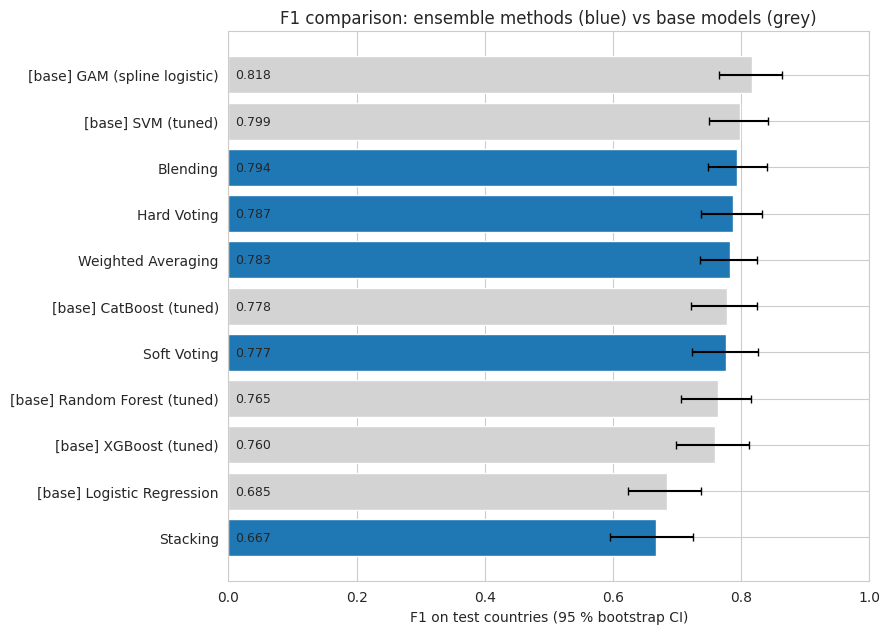

Stage 2 (concentration) ensembles are regressors: F1 is not defined for them; see RMSE / MAE / R2 in 3.13c.


In [37]:
# ---- 3.13f  F1-score comparison of all Stage 1 ensemble methods (test countries) -------------------
# F1 depends on the threshold, so two versions are shown:
#   F1 @ tau(sel)  : tau chosen on the validation countries with THRESHOLD_CRITERION (what the tables above use)
#   F1 @ tau(F1)   : tau chosen on the validation countries to maximise F1 (Hard Voting keeps its 0.5 majority rule)
# The 95 % interval is a row-level bootstrap of the test countries. It ignores clustering by country, so it is optimistic.
y_te = np.asarray(yA_te).astype(int)
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = rng.integers(0, len(y_te), size=(1000, len(y_te)))

def f1_ci(pred):
    s = [f1_score(y_te[i], pred[i], zero_division=0) for i in boot_idx]
    return np.percentile(s, [2.5, 97.5])

members = {**{k: ('Ensemble', r) for k, r in ENS_CLS.items()},
           **{f'[base] {k}': ('Base model', CLS[k]) for k in ENS_CLS_BASE}}
rows = []
for name, (kind, r) in members.items():
    pred = (r['test'] >= r['tau']).astype(int)
    ty, tp = r.get('tau_data', (np.asarray(yA_va), r['val']))
    tau_f1 = 0.5 if name == 'Hard Voting' else select_threshold(ty, tp, 'f1')
    pred_f1 = (r['test'] >= tau_f1).astype(int)
    lo, hi = f1_ci(pred)
    rows.append({'Method': name, 'Type': kind, 'tau (sel)': r['tau'], 'Precision': precision_score(y_te, pred, zero_division=0),
                 'Recall': recall_score(y_te, pred, zero_division=0), 'F1 @ tau(sel)': f1_score(y_te, pred, zero_division=0),
                 'F1 95% CI': f'[{lo:.3f}, {hi:.3f}]', 'tau (F1)': tau_f1, 'F1 @ tau(F1)': f1_score(y_te, pred_f1, zero_division=0)})
F1_TABLE = pd.DataFrame(rows).set_index('Method').sort_values('F1 @ tau(sel)', ascending=False)
num = ['tau (sel)', 'Precision', 'Recall', 'F1 @ tau(sel)', 'tau (F1)', 'F1 @ tau(F1)']
F1_TABLE[num] = F1_TABLE[num].astype(float).round(3)
print(f'Test prevalence = {y_te.mean():.3f}; always-predict-positive F1 = {f1_score(y_te, np.ones_like(y_te)):.3f}')
display(F1_TABLE)

ens = F1_TABLE[F1_TABLE['Type'] == 'Ensemble']; base = F1_TABLE[F1_TABLE['Type'] == 'Base model']
print(f"\nBest ensemble by F1: {ens['F1 @ tau(sel)'].idxmax()} ({ens['F1 @ tau(sel)'].max():.3f}) | "
      f"best base model: {base['F1 @ tau(sel)'].idxmax()} ({base['F1 @ tau(sel)'].max():.3f})")

fig, ax = plt.subplots(figsize=(9, 0.45 * len(F1_TABLE) + 1.5))
plot_df = F1_TABLE.iloc[::-1]
lo_hi = np.array([[float(s.strip('[]').split(',')[0]), float(s.strip('[]').split(',')[1])] for s in plot_df['F1 95% CI']])
err = np.vstack([plot_df['F1 @ tau(sel)'].values - lo_hi[:, 0], lo_hi[:, 1] - plot_df['F1 @ tau(sel)'].values])
colors = ['tab:blue' if t == 'Ensemble' else 'lightgray' for t in plot_df['Type']]
ax.barh(plot_df.index, plot_df['F1 @ tau(sel)'], xerr=err, color=colors, capsize=3)
for i, v in enumerate(plot_df['F1 @ tau(sel)']): ax.text(0.01, i, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlabel('F1 on test countries (95 % bootstrap CI)'); ax.set_xlim(0, 1)
ax.set_title('F1 comparison: ensemble methods (blue) vs base models (grey)'); plt.tight_layout(); plt.show()
print('Stage 2 (concentration) ensembles are regressors: F1 is not defined for them; see RMSE / MAE / R2 in 3.13c.')

In [38]:
# ---- 3.13e  Harness check: every method present, no degenerate base model
expected_cls = {'Hard Voting','Soft Voting','Weighted Averaging','Stacking','Blending'}
expected_reg = {'Simple Averaging','Weighted Averaging','Stacking','Blending'}
print('Stage 1 missing:', sorted(expected_cls - set(ENS_CLS)) or 'none')
print('Stage 2 missing:', sorted(expected_reg - set(ENS_REG)) or 'none')
for k in ENS_CLS_BASE: assert np.nanstd(CLS[k]['test']) > 1e-6, f'{k}: constant predictions'

for k, r in ENS_CLS.items():
    auc = roc_auc_score(yA_te, r['test'])
    if k != 'Hard Voting' and auc < 0.6: print(f'WARNING: {k} test ROC-AUC = {auc:.3f} (near chance) - check the meta-model')

Stage 1 missing: none
Stage 2 missing: none


Stage 1 base model: XGBoost (tuned)
Stage 1 base model: XGBoost (tuned)
Calibration set: n=1039 OOF rows from 19 training countries; prevalence=0.578 (pos=601, neg=438)
Validation prevalence=0.525 (n=240) | test prevalence=0.646 (n=223)

Validation (used for method selection):


,Brier,Log loss,ROC-AUC,PR-AUC,ECE,Cal. slope,Cal. intercept
none,0.2534,0.7667,0.7335,0.7806,0.2077,0.4767,0.5567
platt,0.2177,0.6261,0.7335,0.7806,0.0555,2.1993,0.1241
isotonic,0.2183,0.6269,0.7218,0.7284,0.0673,2.3698,0.1398


Selected calibration: platt  (isotonic eligible: False; n_cal=1039, need >= 1000)

Test (reported only; nothing was fitted or chosen on it):


,Brier,Log loss,ROC-AUC,PR-AUC,ECE,Cal. slope,Cal. intercept
none,0.1889,0.5629,0.8124,0.9047,0.1440,0.8770,0.8376
platt,0.2018,0.5937,0.8124,0.9047,0.1647,4.0510,0.0422
isotonic,0.1955,0.5787,0.7829,0.8497,0.1083,3.3202,0.3823


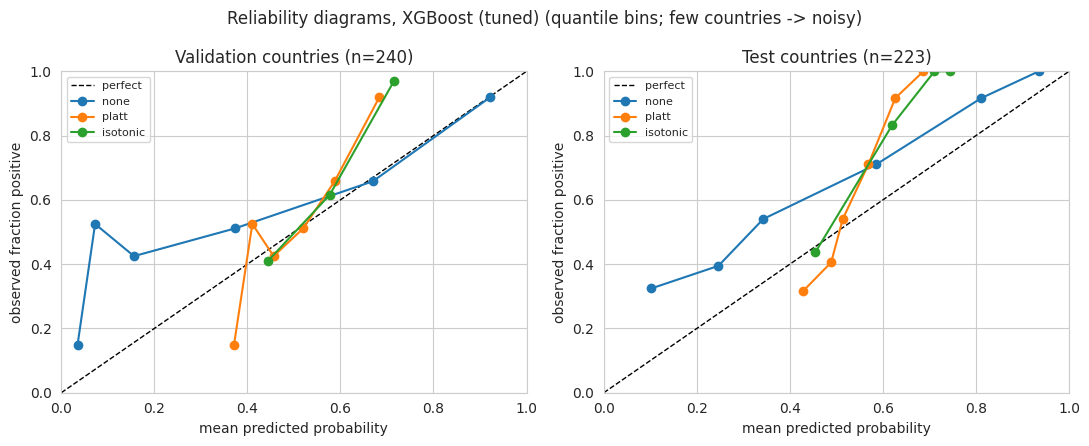

Calibration effect (raw -> platt):
  validation: Brier 0.2534 -> 0.2177, log loss 0.7667 -> 0.6261, ECE 0.208 -> 0.056, slope 0.48 -> 2.20
  test: Brier 0.1889 -> 0.2018, log loss 0.5629 -> 0.5937, ECE 0.144 -> 0.165, slope 0.88 -> 4.05
Improves reliability on TEST (Brier and log loss both lower)? False
ROC-AUC change (should be ~0 for Platt, may drop slightly for isotonic ties): 0.812 -> 0.812
saved /kaggle/working/uq_outputs/smx_calibrated_occurrence_probabilities.csv (463, 12)
Stage 2 point model: Linear Regression
Stage 2 point model: Linear Regression
n calibration residuals = 601; q(adaptive, standardised) = 2.285; q(constant, log10 units) = 1.219; scale floor = 0.123
Target coverage = 90%. Validation check (rows NOT in the calibration set; used only to pick the variant):


,n,Coverage,Wilson 95% lo,Wilson 95% hi,Mean width (log10),Mean width (ng/L),Median width (ng/L),Lower clipped (%),Unavailable (%)
adaptive | validation,126.0,0.952,0.90,0.978,2.092,583.383,211.057,46.032,0.0
constant | validation,126.0,0.937,0.88,0.967,2.045,445.144,191.703,62.698,0.0


Selected interval variant (validation coverage closest to nominal, then narrower): constant

Test countries, quantified samples (reported only):


,n,Coverage,Wilson 95% lo,Wilson 95% hi,Mean width (log10),Mean width (ng/L),Median width (ng/L),Lower clipped (%),Unavailable (%)
adaptive | test,144.0,0.965,0.921,0.985,2.563,1057.434,612.154,64.583,0.0
constant | test,144.0,0.979,0.941,0.993,2.095,368.815,132.789,64.583,0.0


Coverage by country (rows with n < 15 are marked reportable=False; Wilson CI shows how little they say):


...

Quantified samples only (the only rows with a concentration truth):


,n,coverage,coverage_valid_only,mean_width_ngL,mean_width_log10
split,,,,,
test,144,0.979,0.981,368.815,2.095
validation,126,0.937,0.925,445.144,2.045


Non-quantified samples: no concentration truth, so no coverage. Conflict rate (whole interval above the LoQ although not quantified):


,size,mean
split,,
test,79,0.519
validation,114,0.096


"All-sample" numbers above are NOT coverage: conditional intervals on quantified samples are not valid statements about non-quantified samples.


In [39]:
# %% [markdown]
# # 3.13U Uncertainty quantification (appended after the ensemble section 3.13)
# *(Numbered 3.13U only because your notebook already has an ensemble section called 3.13; rename as needed.)*
#
# Runs after Sections 3.6-3.13 and reuses `CLS`, `REG`, `ENS_CLS_BASE`, `ENS_REG_BASE`, the grouped masks `mask_A` / `mask_B`,
# `oof_predictions`, `make_prep`, `predict_reg`, and the metric helpers. **No test outcome is used to fit, select or tune
# anything below**; test rows are only scored after every choice is frozen.
#
# Design in one table:
#
# | Part | Fitted on | Method/threshold chosen on | Scored on |
# |---|---|---|---|
# | 3.1 Calibration (Stage 1) | country-grouped out-of-fold predictions of the **training** countries | validation countries | validation (selection) + test (report) |
# | 3.2 Conformal intervals (Stage 2) | country-grouped out-of-fold residuals of the **training** countries | validation coverage/width | validation + test |
# | 3.3 Categories | thresholds from validation calibrated probabilities / widths | validation only | test (descriptive) |

# %%
import math
from pathlib import Path
from sklearn.metrics import log_loss
from sklearn.model_selection import GroupKFold

UQ = dict(
    STAGE1_MODEL=None,        # None -> best validation PR-AUC among ENS_CLS_BASE
    STAGE2_MODEL=None,        # None -> best validation RMSE among ENS_REG_BASE
    ALPHA=0.10,               # 90 % intervals
    ISO_MIN_N=1000,           # isotonic only considered if the calibration set is at least this large
    ISO_MARGIN=0.02,          # ...and it must beat Platt by >2 % (relative) on validation Brier AND log loss
    MIN_N_SUBGROUP=15,        # minimum quantified samples for a per-country / per-matrix coverage row
    MISSING_MAX=0.30,         # flag samples with >30 % missing input features
    OOD_Q=(0.01, 0.99),       # training-range quantiles used for the OOD check
    OOD_MIN_FEATURES=3,       # flag if >= this many numeric features fall outside the training quantile range
    PRECISION_TARGET=0.75,    # high-probability threshold: smallest tau with validation precision >= target
    NPV_TARGET=0.75,          # low-probability threshold: largest tau with validation NPV >= target
    MIN_SUPPORT=20,           # minimum validation samples behind a data-driven threshold
    FALLBACK_P=(0.35, 0.65),  # (low, high) if the targets are unattainable on validation
    WIDTH_QUANTILE=0.50,      # narrow/wide split = this quantile of validation interval widths (log10 units)
)
UQ_OUT = Path('/kaggle/working/uq_outputs') if Path('/kaggle/working').exists() else Path('uq_outputs')
UQ_OUT.mkdir(parents=True, exist_ok=True)

def _lg(p, eps=1e-4):
    p = np.clip(np.asarray(p, float), eps, 1 - eps); return np.log(p / (1 - p))

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n)
    a = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)); return ((c - a) / d, (c + a) / d)

# %% [markdown]
# ## 3.1 Calibrated SMX occurrence probabilities
#
# **Base classifier.** The Stage 1 model with the best *validation* PR-AUC (override with `UQ['STAGE1_MODEL']`). Its
# validation/test probabilities come from the model already refit on the training countries.
#
# **Calibration set.** Country-grouped out-of-fold (OOF) predictions on the training countries (`oof_predictions`: each
# fold's countries are never in that fold's training data). This mimics "predict for an unseen country", uses ~1,000 rows
# instead of the ~240 validation rows (isotonic on 240 rows is very noisy), and keeps the validation countries free for
# **choosing** the method. Test outcomes are never touched.
#
# **Candidates.** Platt (logistic on logit p), isotonic, or none. Rule (fixed before looking at results):
# isotonic only if the calibration set has >= `ISO_MIN_N` rows **and** it beats Platt by >`ISO_MARGIN` (relative) on both
# validation Brier and validation log loss; if neither calibrator improves on the raw probabilities on both metrics, keep raw.

# %%
# Select the Stage 1 classifier with the best validation PR-AUC
if UQ['STAGE1_MODEL'] is not None:
    uq_s1 = UQ['STAGE1_MODEL']
else:
    cls_candidates = [
        k for k in CLS
        if 'val' in CLS[k]
        and CLS[k]['val'] is not None
        and len(CLS[k]['val']) == len(yA_va)
        and np.isfinite(np.asarray(CLS[k]['val'], dtype=float)).all()
    ]

    if not cls_candidates:
        raise ValueError("No valid Stage 1 validation predictions found.")

    uq_s1 = max(
        cls_candidates,
        key=lambda k: average_precision_score(
            yA_va, CLS[k]['val']
        )
    )

p_va_raw = np.asarray(CLS[uq_s1]['val'], dtype=float)
p_te_raw = np.asarray(CLS[uq_s1]['test'], dtype=float)

print('Stage 1 base model:', uq_s1)
p_va_raw, p_te_raw = np.asarray(CLS[uq_s1]['val'], float), np.asarray(CLS[uq_s1]['test'], float)
print('Stage 1 base model:', uq_s1)

oof1 = oof_predictions('cls', [uq_s1], XA_tr, yA_tr, df_occ.loc[mask_A['train'], 'country'])
ok1 = oof1[uq_s1].notna().values
p_fit, y_fit = oof1[uq_s1].values[ok1], np.asarray(yA_tr)[ok1].astype(int)
print(f'Calibration set: n={len(y_fit)} OOF rows from {df_occ.loc[mask_A["train"], "country"].nunique()} training countries; '
      f'prevalence={y_fit.mean():.3f} (pos={y_fit.sum()}, neg={(1-y_fit).sum()})')
print(f'Validation prevalence={np.mean(yA_va):.3f} (n={len(yA_va)}) | test prevalence={np.mean(yA_te):.3f} (n={len(yA_te)})')

def fit_platt(p, y):
    lr = LogisticRegression(C=1e6, max_iter=5000).fit(_lg(p).reshape(-1, 1), y)
    return lambda q: lr.predict_proba(_lg(q).reshape(-1, 1))[:, 1]
def fit_iso(p, y):
    ir = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds='clip').fit(p, y)
    return lambda q: np.asarray(ir.predict(np.asarray(q, float)), float)

CAL = {'none': lambda q: np.asarray(q, float), 'platt': fit_platt(p_fit, y_fit), 'isotonic': fit_iso(p_fit, y_fit)}

def uq_prob_metrics(y, p):
    y = np.asarray(y).astype(int); p = np.clip(np.asarray(p, float), 1e-4, 1 - 1e-4)
    slope, icpt = calibration_slope(y, p)
    return {'Brier': brier_score_loss(y, p), 'Log loss': log_loss(y, p, labels=[0, 1]), 'ROC-AUC': roc_auc_score(y, p),
            'PR-AUC': average_precision_score(y, p), 'ECE': expected_calibration_error(y, p),
            'Cal. slope': slope, 'Cal. intercept': icpt}

VAL_M = {m: uq_prob_metrics(yA_va, f(p_va_raw)) for m, f in CAL.items()}
print('\nValidation (used for method selection):'); display(pd.DataFrame(VAL_M).T.round(4))

pl, iso, raw = VAL_M['platt'], VAL_M['isotonic'], VAL_M['none']
iso_ok = (len(y_fit) >= UQ['ISO_MIN_N']
          and iso['Brier'] < pl['Brier'] * (1 - UQ['ISO_MARGIN']) and iso['Log loss'] < pl['Log loss'] * (1 - UQ['ISO_MARGIN']))
best = 'isotonic' if iso_ok else 'platt'
if not (VAL_M[best]['Brier'] < raw['Brier'] or VAL_M[best]['Log loss'] < raw['Log loss']):
    best = 'none'          # calibration hurts on BOTH metrics on validation -> keep raw
UQ_CAL = best
print(f'Selected calibration: {UQ_CAL}  (isotonic eligible: {iso_ok}; n_cal={len(y_fit)}, need >= {UQ["ISO_MIN_N"]})')

p_va_cal, p_te_cal = CAL[UQ_CAL](p_va_raw), CAL[UQ_CAL](p_te_raw)
TE_M = {m: uq_prob_metrics(yA_te, f(p_te_raw)) for m, f in CAL.items()}
print('\nTest (reported only; nothing was fitted or chosen on it):'); display(pd.DataFrame(TE_M).T.round(4))

# %%
def reliability(ax, y, p_dict, title, n_bins=6):
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='perfect')
    for name, p in p_dict.items():
        fy, fp = calibration_curve(y, np.clip(p, 0, 1), n_bins=n_bins, strategy='quantile')
        ax.plot(fp, fy, marker='o', label=name)
    ax.set_xlabel('mean predicted probability'); ax.set_ylabel('observed fraction positive'); ax.set_title(title)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
reliability(axes[0], yA_va, {m: f(p_va_raw) for m, f in CAL.items()}, f'Validation countries (n={len(yA_va)})')
reliability(axes[1], yA_te, {m: f(p_te_raw) for m, f in CAL.items()}, f'Test countries (n={len(yA_te)})')
plt.suptitle(f'Reliability diagrams, {uq_s1} (quantile bins; few countries -> noisy)'); plt.tight_layout(); plt.show()

# Verdict computed from the numbers (not asserted)
def _delta(M, k): return M[UQ_CAL][k] - M['none'][k]
verdict = []
for nm, M in (('validation', VAL_M), ('test', TE_M)):
    verdict.append(f"{nm}: Brier {M['none']['Brier']:.4f} -> {M[UQ_CAL]['Brier']:.4f}, log loss {M['none']['Log loss']:.4f} -> {M[UQ_CAL]['Log loss']:.4f}, "
                   f"ECE {M['none']['ECE']:.3f} -> {M[UQ_CAL]['ECE']:.3f}, slope {M['none']['Cal. slope']:.2f} -> {M[UQ_CAL]['Cal. slope']:.2f}")
print('Calibration effect (raw -> %s):' % UQ_CAL); [print('  ' + v) for v in verdict]
print('Improves reliability on TEST (Brier and log loss both lower)?',
      bool(_delta(TE_M, 'Brier') < 0 and _delta(TE_M, 'Log loss') < 0))
print('ROC-AUC change (should be ~0 for Platt, may drop slightly for isotonic ties): '
      f"{TE_M['none']['ROC-AUC']:.3f} -> {TE_M[UQ_CAL]['ROC-AUC']:.3f}")

# Save calibrated occurrence probabilities for the evaluated (validation + test) samples
def occ_frame(mask, p_raw, split):
    d = df_occ.loc[mask, ['site_id', 'country', 'water_matrix', 'sampling_date']].copy()
    d['split'] = split; d['y_occ'] = y_occ.loc[mask].values; d['p_raw'] = p_raw
    d['p_platt'] = CAL['platt'](p_raw); d['p_isotonic'] = CAL['isotonic'](p_raw)
    d['p_calibrated'] = CAL[UQ_CAL](p_raw); d['calibration_method'] = UQ_CAL; d['stage1_model'] = uq_s1
    return d
OCC = pd.concat([occ_frame(mask_A['val'], p_va_raw, 'validation'), occ_frame(mask_A['test'], p_te_raw, 'test')])
OCC.to_csv(UQ_OUT / 'smx_calibrated_occurrence_probabilities.csv', index=False); print('saved', UQ_OUT / 'smx_calibrated_occurrence_probabilities.csv', OCC.shape)

# %% [markdown]
# **How to read 3.1 (limitations to state in the paper).**
# * The calibration mapping is learned on training-country OOF predictions and **evaluated on a handful of held-out countries**
#   (4 validation, 4 test). Country mix, not just sample size, drives calibration error; the reliability curves are noisy
#   (quantile bins of ~40 samples) and one country can move them.
# * Class imbalance: prevalence differs by split (printed above). Brier/log loss are prevalence-sensitive, so compare
#   calibrated vs raw **within** a split, not across splits. The OOF mapping assumes the unseen country behaves like the
#   training-country OOF folds; a prevalence shift is not corrected by Platt/isotonic.
# * Calibration does not change ranking for Platt (monotone) and cannot fix poor discrimination: if ROC-AUC is ~0.65-0.80,
#   even perfectly calibrated probabilities stay close to the base rate for many samples.
# * Isotonic needs more data (rule above) and creates ties/plateaus; that is why Platt is the default here.
# * Verdict is printed from the numbers above. "Improves reliability" means lower Brier **and** log loss and a slope nearer 1
#   on the test countries, with the caveat of 4 countries.

# %% [markdown]
# ## 3.2 Ninety-percent prediction intervals for SMX concentration (Stage 2)
#
# **What is predicted.** Stage 2 predicts `y = log10(C + 1)` **conditional on the sample being quantified** (trained on Dataset B).
# The intervals are conditional intervals; they are *not* the probability of occurrence and *not* the unconditional expected
# concentration (`P(occ) * E[C | quantified]`).
#
# **Method: grouped split-conformal with adaptive width (locally-weighted), with a constant-width variant as comparator.**
# * Point model: the Stage 2 regressor with best validation RMSE (override `UQ['STAGE2_MODEL']`), refit on the training countries.
#   Predictions are clipped at 0 on the log scale, which is lossless because `y = log10(C+1) >= 0` for every sample.
# * Calibration scores: **cross-fitted** country-grouped OOF residuals on the training countries (every residual comes from a model that
#   did not see that country). Validation and test countries are not in the calibration set.
# * Nonconformity score: `a_i = |y_i - yhat_i| / s(x_i)` for the adaptive variant, where `s(x)` is a random-forest model of the
#   OOF absolute residual (itself country-grouped cross-fitted, floored at 25 % of the median residual); `a_i = |y_i - yhat_i|` for the constant variant.
# * Interval on the log scale: `yhat +/- q * s(x)`, where `q` is the `ceil((n+1)(1-alpha))/n` empirical quantile of the scores (finite-sample correction).
#   `q = inf` (interval unavailable) is returned if `n` is too small.
# * Back-transform to ng/L with `C = 10^y - 1`; quantiles/intervals map exactly through a monotone transform, so log-scale coverage equals ng/L coverage.
#   The lower log bound is truncated at 0 (so the lower concentration is >= 0 ng/L). Because `y >= 0` always, this truncation **cannot remove a covered point**; the code
#   asserts that coverage with and without it is identical and flags every truncated sample (`lower_clipped`). The back-transformed point is a *median-type* estimate, not the mean in ng/L (retransformation bias).
#
# **Coverage guarantee and when it fails.** Marginal coverage `>= 1-alpha` holds if calibration and target samples are exchangeable. Here the target samples
# are *unseen countries*, so the realistic claim is **approximate** coverage: country-grouped cross-fitting makes the residuals "unseen-country-like",
# but real exchangeability across countries is not guaranteed, coverage is marginal (not per country/matrix), and it degrades under covariate shift,
# new water matrices, or changes in analytical method/LoQ. Coverage on the validation/test countries below is the empirical check of that.

# %%
# Select the Stage 2 regressor with the lowest validation RMSE
if UQ['STAGE2_MODEL'] is not None:
    uq_s2 = UQ['STAGE2_MODEL']
else:
    reg_candidates = [
        k for k in REG
        if 'val' in REG[k]
        and REG[k]['val'] is not None
        and len(REG[k]['val']) == len(yB_va)
        and np.isfinite(np.asarray(REG[k]['val'], dtype=float)).all()
    ]

    if not reg_candidates:
        raise ValueError("No valid Stage 2 validation predictions found.")

    uq_s2 = min(
        reg_candidates,
        key=lambda k: np.sqrt(
            mean_squared_error(yB_va, REG[k]['val'])
        )
    )

print('Stage 2 point model:', uq_s2)
print('Stage 2 point model:', uq_s2)
pipe2 = _label_to_pipe(uq_s2, 'reg').fit(XB_tr, yB_tr)

oofB = oof_predictions('reg', [uq_s2], XB_tr, yB_tr, df_conc.loc[mask_B['train'], 'country'])
okB = oofB[uq_s2].notna().values
idxB = np.where(okB)[0]
XBc = XB_tr.iloc[idxB]; yBc = np.asarray(yB_tr)[idxB]
yhat_oof = np.clip(oofB[uq_s2].values[idxB], 0, None)        # same clipping as predict_reg
res = np.abs(yBc - yhat_oof)
gB = _groups_clean(df_conc.loc[mask_B['train'], 'country'])[idxB]

def make_scale():
    return Pipeline([('prep', make_prep(scale=False)),
                     ('m', RandomForestRegressor(n_estimators=300, min_samples_leaf=10, random_state=RANDOM_STATE, n_jobs=N_JOBS))])

s_oof = np.full(len(res), np.nan)
for tr, te in GroupKFold(n_splits=min(5, len(np.unique(gB)))).split(XBc, res, gB):
    s_oof[te] = make_scale().fit(XBc.iloc[tr], res[tr]).predict(XBc.iloc[te])
S_FLOOR = 0.25 * float(np.median(res))
s_oof = np.clip(s_oof, S_FLOOR, None)
scale_full = make_scale().fit(XBc, res)

def conformal_q(scores, alpha):
    n = len(scores); k = math.ceil((n + 1) * (1 - alpha))
    return float(np.sort(scores)[k - 1]) if k <= n else np.inf
Q_AD = conformal_q(res / s_oof, UQ['ALPHA']); Q_CT = conformal_q(res, UQ['ALPHA'])
print(f'n calibration residuals = {len(res)}; q(adaptive, standardised) = {Q_AD:.3f}; q(constant, log10 units) = {Q_CT:.3f}; scale floor = {S_FLOOR:.3f}')

def to_ngL(y): return 10 ** np.asarray(y, float) - 1

def interval_log(X, variant):
    yhat = predict_reg(pipe2, X)
    h = Q_AD * np.clip(scale_full.predict(X), S_FLOOR, None) if variant == 'adaptive' else np.full(len(X), Q_CT)
    lo_raw, hi = yhat - h, yhat + h
    return yhat, lo_raw, np.maximum(lo_raw, 0.0), hi

def interval_report(y, X, variant):
    yhat, lo_raw, lo, hi = interval_log(X, variant); y = np.asarray(y, float)
    cov_raw = ((y >= lo_raw) & (y <= hi)); cov = ((y >= lo) & (y <= hi))
    assert (cov_raw == cov).all(), 'lower truncation changed coverage (should be impossible since y >= 0)'
    k, n = int(cov.sum()), len(y); wl = wilson(k, n)
    return {'n': n, 'Coverage': k / n, 'Wilson 95% lo': wl[0], 'Wilson 95% hi': wl[1], 'Mean width (log10)': float((hi - lo).mean()),
            'Mean width (ng/L)': float((to_ngL(hi) - to_ngL(lo)).mean()), 'Median width (ng/L)': float(np.median(to_ngL(hi) - to_ngL(lo))),
            'Lower clipped (%)': float((lo_raw < 0).mean() * 100), 'Unavailable (%)': float((~np.isfinite(hi)).mean() * 100)}

rows = {}
for variant in ('adaptive', 'constant'):
    rows[f'{variant} | validation'] = interval_report(yB_va, XB_va, variant)
print(f"Target coverage = {1 - UQ['ALPHA']:.0%}. Validation check (rows NOT in the calibration set; used only to pick the variant):")
display(pd.DataFrame(rows).T.round(3))
v_ad, v_ct = rows['adaptive | validation'], rows['constant | validation']
d_ad, d_ct = abs(v_ad['Coverage'] - (1 - UQ['ALPHA'])), abs(v_ct['Coverage'] - (1 - UQ['ALPHA']))
UQ_VARIANT = 'adaptive' if (d_ad < d_ct - 1e-9 or (abs(d_ad - d_ct) <= 1e-9 and v_ad['Mean width (log10)'] <= v_ct['Mean width (log10)'])) else 'constant'
print('Selected interval variant (validation coverage closest to nominal, then narrower):', UQ_VARIANT)

TEST_ROWS = {f'{v} | test': interval_report(yB_te, XB_te, v) for v in ('adaptive', 'constant')}
print('\nTest countries, quantified samples (reported only):'); display(pd.DataFrame(TEST_ROWS).T.round(3))

# %%
# Coverage by country and by water matrix (validation + test countries, quantified samples only)
vt_B = mask_B['val'] | mask_B['test']
Xvt, yvt = X_conc.loc[vt_B], y_conc.loc[vt_B].values
_, lo_raw_, lo_, hi_ = interval_log(Xvt, UQ_VARIANT)
cov_vt = ((yvt >= lo_) & (yvt <= hi_))
meta = df_conc.loc[vt_B, ['country', 'water_matrix']].assign(covered=cov_vt, split=np.where(mask_B['val'][vt_B], 'validation', 'test'),
                                                             w=(hi_ - lo_))
def sub_cov(col):
    g = meta.groupby([col, 'split']).agg(n=('covered', 'size'), coverage=('covered', 'mean'), mean_width_log10=('w', 'mean')).reset_index()
    g['reportable'] = g['n'] >= UQ['MIN_N_SUBGROUP']
    g[['ci_lo', 'ci_hi']] = [wilson(int(round(c * n)), int(n)) for c, n in zip(g['coverage'], g['n'])]
    return g.sort_values(['split', 'n'], ascending=[True, False]).round(3)
print(f'Coverage by country (rows with n < {UQ["MIN_N_SUBGROUP"]} are marked reportable=False; Wilson CI shows how little they say):'); display(sub_cov('country'))
print('Coverage by water matrix:'); display(sub_cov('water_matrix'))

# %% [markdown]
# ### Eligibility, validity flags and saving per-sample intervals (all evaluated samples)
# Intervals are produced for **all validation + test samples in Dataset A** (quantified or not) because Stage 2 is a function of
# the covariates; but they are *conditional on quantification*, and coverage can only be **evaluated on quantified samples**
# (concentration is censored otherwise). For non-quantified samples the only available sanity check is a *conflict rate*:
# the share whose whole interval lies above the LoQ although the sample was not quantified (the conditional model implicitly assumes "quantified").
#
# Flags: `interval_available` (finite bounds), `missing_inputs` (> `MISSING_MAX` of features missing), `out_of_distribution`
# (>= `OOD_MIN_FEATURES` numeric features outside the training 1-99 % range, or an unseen water matrix),
# `interval_valid = available & ~missing_inputs & ~out_of_distribution`.

# %%
tr_num = XA_tr[num_cols]
q_lo, q_hi = tr_num.quantile(UQ['OOD_Q'][0]), tr_num.quantile(UQ['OOD_Q'][1])
seen_matrix = set(XA_tr['water_matrix'].dropna().unique()) if 'water_matrix' in XA_tr else set()

def sample_flags(X):
    miss = X[FEATURES].isna().mean(axis=1).values
    out = ((X[num_cols] < q_lo) | (X[num_cols] > q_hi)).sum(axis=1).values
    unseen = (~X['water_matrix'].isin(seen_matrix)).values if 'water_matrix' in X else np.zeros(len(X), bool)
    return miss, out, unseen

def interval_frame(mask, split):
    X = X_occ.loc[mask]; yhat, lo_raw, lo, hi = interval_log(X, UQ_VARIANT)
    miss, out, unseen = sample_flags(X)
    d = df_occ.loc[mask, ['site_id', 'country', 'water_matrix', 'sampling_date', 'detection_status', 'LoQ']].copy()
    d['split'] = split; d['quantified'] = (d['detection_status'] == 'quantified').astype(int)
    d['y_true_log10'] = np.where(d['quantified'] == 1, y_occ.loc[mask].values * 0 + np.log10(df_occ.loc[mask, 'concentration_ng_L'].values + 1), np.nan)
    d['pred_log10'] = yhat; d['lower_log10_raw'] = lo_raw; d['lower_log10'] = lo; d['upper_log10'] = hi
    d['lower_ngL'] = to_ngL(lo); d['point_ngL'] = to_ngL(yhat); d['upper_ngL'] = to_ngL(hi)
    d['width_ngL'] = d['upper_ngL'] - d['lower_ngL']; d['width_log10'] = hi - lo
    d['lower_clipped'] = (lo_raw < 0).astype(int)
    d['interval_available'] = np.isfinite(hi) & np.isfinite(yhat)
    d['missing_frac'] = miss; d['missing_inputs'] = miss > UQ['MISSING_MAX']
    d['n_features_outside_train_range'] = out
    d['out_of_distribution'] = (out >= UQ['OOD_MIN_FEATURES']) | unseen
    d['interval_valid'] = d['interval_available'] & ~d['missing_inputs'] & ~d['out_of_distribution']
    d['interval_variant'] = UQ_VARIANT; d['stage2_model'] = uq_s2
    d['covered'] = np.where(d['quantified'] == 1, ((d['y_true_log10'] >= lo) & (d['y_true_log10'] <= hi)).astype(float), np.nan)
    return d

INT = pd.concat([interval_frame(mask_A['val'], 'validation'), interval_frame(mask_A['test'], 'test')])
INT.to_csv(UQ_OUT / 'smx_concentration_intervals_90.csv', index=False)
print('saved', UQ_OUT / 'smx_concentration_intervals_90.csv', INT.shape)

summ = INT.groupby('split').agg(n=('site_id', 'size'), quantified=('quantified', 'sum'), available=('interval_available', 'mean'),
                                missing_flag=('missing_inputs', 'mean'), ood_flag=('out_of_distribution', 'mean'), valid=('interval_valid', 'mean'),
                                clipped=('lower_clipped', 'mean'))
print('Flag rates:'); display(summ.round(3))

q = INT[INT['quantified'] == 1]
print('Quantified samples only (the only rows with a concentration truth):')
display(q.groupby('split').agg(n=('covered', 'size'), coverage=('covered', 'mean'), coverage_valid_only=('covered', lambda s: s[q.loc[s.index, 'interval_valid'].values].mean() if q.loc[s.index, 'interval_valid'].any() else np.nan),
                                mean_width_ngL=('width_ngL', 'mean'), mean_width_log10=('width_log10', 'mean')).round(3))
nq = INT[INT['quantified'] == 0].copy(); nq['conflict'] = nq['lower_ngL'] > nq['LoQ']
print('Non-quantified samples: no concentration truth, so no coverage. Conflict rate (whole interval above the LoQ although not quantified):')
display(nq.groupby('split')['conflict'].agg(['size', 'mean']).round(3))
print('"All-sample" numbers above are NOT coverage: conditional intervals on quantified samples are not valid statements about non-quantified samples.')




# Final table (test): thresholds frozen above. Outcome columns are DESCRIPTIVE diagnostics, not used to tune anything.



# 3.3 Uncertainty categories (occurrence probability x interval width)
#
# Thresholds are set **from the validation countries only** and then frozen:
#  `tau_high` = smallest calibrated-probability threshold with validation precision >= `PRECISION_TARGET` (>= `MIN_SUPPORT` samples);
#  `tau_low` = largest threshold with validation negative predictive value >= `NPV_TARGET` (>= `MIN_SUPPORT` samples);
#   if a target is unattainable, the documented fallback (`FALLBACK_P`) is used. Probabilities between the two thresholds are **moderate** and get their own categories.
#  narrow/wide: width (log10 units, i.e. a *multiplicative* uncertainty factor of 10^width) <= `WIDTH_QUANTILE` quantile of validation interval widths.
#
# A sensitivity table shows how category shares move with other thresholds (validation rows only; no test outcomes are inspected to choose anything).
# Flagged samples (unavailable interval, missing inputs, OOD) are **not** assigned a confident category.


In [40]:
CAL_VA = occ_frame(mask_A['val'], p_va_raw, 'validation').reset_index(drop=True)
CAL_TE = occ_frame(mask_A['test'], p_te_raw, 'test').reset_index(drop=True)
IV_VA = INT[INT['split'] == 'validation'].reset_index(drop=True); IV_TE = INT[INT['split'] == 'test'].reset_index(drop=True)
assert (CAL_VA['site_id'].values == IV_VA['site_id'].values).all() and (CAL_TE['site_id'].values == IV_TE['site_id'].values).all()

pv, yv = CAL_VA['p_calibrated'].values, CAL_VA['y_occ'].values
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
hi_c = [t for t in grid if (pv >= t).sum() >= UQ['MIN_SUPPORT'] and yv[pv >= t].mean() >= UQ['PRECISION_TARGET']]
lo_c = [t for t in grid if (pv <= t).sum() >= UQ['MIN_SUPPORT'] and (1 - yv[pv <= t]).mean() >= UQ['NPV_TARGET']]
TAU_HI = min(hi_c) if hi_c else UQ['FALLBACK_P'][1]
TAU_LO = max(lo_c) if lo_c else UQ['FALLBACK_P'][0]
src = {'high': 'data-driven' if hi_c else 'fallback', 'low': 'data-driven' if lo_c else 'fallback'}
if TAU_LO >= TAU_HI: TAU_LO, TAU_HI = UQ['FALLBACK_P']; src = {'high': 'fallback', 'low': 'fallback'}
vw = IV_VA.loc[IV_VA['interval_valid'], 'width_log10'].values
W_THR = float(np.quantile(vw, UQ['WIDTH_QUANTILE'])) if len(vw) else np.nan
print(f"tau_low={TAU_LO:.2f} ({src['low']}), tau_high={TAU_HI:.2f} ({src['high']}); narrow/wide cut = {W_THR:.3f} log10 units "
      f"(x{10**W_THR:.2f} multiplicative) = validation {UQ['WIDTH_QUANTILE']:.0%} quantile of valid widths (n={len(vw)})")

CATS = {1: 'High-confidence monitoring priority (high occurrence, narrow interval)',
        2: 'High priority but uncertain; confirmatory monitoring required (high occurrence, wide interval)',
        3: 'Lower monitoring priority (low occurrence, narrow interval)',
        4: 'Insufficient evidence; additional data required (low occurrence, wide interval)',
        5: 'Moderate occurrence, narrow interval: intermediate priority, review with local context',
        6: 'Moderate occurrence, wide interval: uncertain, additional/confirmatory data advised',
        0: 'Flagged: no confident category'}

def categorize(P, IV, tau_lo, tau_hi, w_thr):
    p, w = P['p_calibrated'].values, IV['width_log10'].values
    reasons = []
    for a, b, c in zip(~IV['interval_available'].values | ~np.isfinite(w) | ~np.isfinite(p), IV['missing_inputs'].values, IV['out_of_distribution'].values):
        r = [t for t, f in (('interval unavailable', a), ('missing inputs', b), ('out-of-distribution', c)) if f]
        reasons.append('; '.join(r))
    cid = np.zeros(len(p), int)
    for i in range(len(p)):
        if reasons[i]: continue
        wide = w[i] > w_thr
        cid[i] = (2 if wide else 1) if p[i] >= tau_hi else (4 if wide else 3) if p[i] <= tau_lo else (6 if wide else 5)
    out = pd.DataFrame({'category_id': cid, 'category': [CATS[c] for c in cid], 'flag_reason': reasons})
    out['occurrence_uncertainty'] = 1 - np.abs(2 * p - 1)         # 0 = confident either way, 1 = p = 0.5 (separate from interval width)
    return out

CAT_VA = categorize(CAL_VA, IV_VA, TAU_LO, TAU_HI, W_THR); CAT_TE = categorize(CAL_TE, IV_TE, TAU_LO, TAU_HI, W_THR)

print('Validation category shares (thresholds were set here, so this is descriptive):'); display(CAT_VA['category_id'].value_counts(normalize=True).sort_index().round(3).to_frame('share'))


tau_low=0.39 (data-driven), tau_high=0.54 (data-driven); narrow/wide cut = 2.438 log10 units (x274.29 multiplicative) = validation 50% quantile of valid widths (n=126)
Validation category shares (thresholds were set here, so this is descriptive):


,share
category_id,
0,0.475
1,0.300
5,0.225


# Sensitivity of validation category shares to alternative thresholds

In [41]:

sens = []
for wq in (0.33, 0.50, 0.67):
    for lo_t, hi_t in ((0.30, 0.70), (0.35, 0.65), (0.40, 0.60), (TAU_LO, TAU_HI)):
        c = categorize(CAL_VA, IV_VA, lo_t, hi_t, float(np.quantile(vw, wq)))['category_id'].value_counts(normalize=True)
        sens.append({'width quantile': wq, 'tau_low': round(lo_t, 2), 'tau_high': round(hi_t, 2), **{f'cat{k}': round(float(c.get(k, 0)), 3) for k in (1, 2, 3, 4, 5, 6, 0)}})
print('Sensitivity (validation shares of categories 1-6 and flagged=0):'); display(pd.DataFrame(sens))


Sensitivity (validation shares of categories 1-6 and flagged=0):


,width quantile,tau_low,tau_high,cat1,cat2,cat3,cat4,cat5,cat6,cat0
0,0.33,0.30,0.70,0.000,0.058,0.0,0.0,0.179,0.287,0.475
1,0.33,0.35,0.65,0.017,0.117,0.0,0.0,0.163,0.229,0.475
2,0.33,0.40,0.60,0.037,0.175,0.0,0.0,0.142,0.171,0.475
3,0.33,0.39,0.54,0.087,0.212,0.0,0.0,0.092,0.133,0.475
4,0.50,0.30,0.70,0.058,0.000,0.0,0.0,0.467,0.000,0.475
5,0.50,0.35,0.65,0.133,0.000,0.0,0.0,0.392,0.000,0.475
6,0.50,0.40,0.60,0.212,0.000,0.0,0.0,0.312,0.000,0.475
7,0.50,0.39,0.54,0.300,0.000,0.0,0.0,0.225,0.000,0.475
8,0.67,0.30,0.70,0.058,0.000,0.0,0.0,0.467,0.000,0.475
9,0.67,0.35,0.65,0.133,0.000,0.0,0.0,0.392,0.000,0.475


# Final table (test): thresholds frozen above. Outcome columns are DESCRIPTIVE diagnostics, not used to tune anything.

In [42]:
FINAL = pd.concat([pd.concat([CAL_VA, IV_VA.drop(columns=['site_id', 'country', 'water_matrix', 'sampling_date', 'split']), CAT_VA], axis=1),
                   pd.concat([CAL_TE, IV_TE.drop(columns=['site_id', 'country', 'water_matrix', 'sampling_date', 'split']), CAT_TE], axis=1)])
FINAL['tau_low'] = TAU_LO; FINAL['tau_high'] = TAU_HI; FINAL['width_threshold_log10'] = W_THR
FINAL.to_csv(UQ_OUT / 'smx_uncertainty_categories.csv', index=False)
print('saved', UQ_OUT / 'smx_uncertainty_categories.csv', FINAL.shape)

t = FINAL[FINAL['split'] == 'test']
diag = t.groupby('category_id').agg(n=('site_id', 'size'), mean_p_cal=('p_calibrated', 'mean'), observed_occurrence=('y_occ', 'mean'),
                                    n_quantified=('quantified', 'sum'), interval_coverage_quantified=('covered', 'mean'), median_width_ngL=('width_ngL', 'median')).round(3)
diag.insert(0, 'label', [CATS[i][:45] for i in diag.index]); print('Test-country diagnostics per category (descriptive only):'); display(diag)


saved /kaggle/working/uq_outputs/smx_uncertainty_categories.csv (463, 42)
Test-country diagnostics per category (descriptive only):


,label,n,mean_p_cal,observed_occurrence,n_quantified,interval_coverage_quantified,median_width_ngL
category_id,,,,,,,
0,Flagged: no confident category,98,0.509,0.398,39,0.974,411.934
1,High-confidence monitoring priority (high occ,77,0.641,0.922,71,0.986,84.216
5,"Moderate occurrence, narrow interval: interme",48,0.494,0.708,34,0.971,121.574
